# <center> <img src="figs/LogoUFSCar.jpg" alt="Logo UFScar" width="110" align="left"/>  <br/> <center>Universidade Federal de São Carlos (UFSCar)<br/><font size="4"> Departamento de Computação, campus Sorocaba</center></font>
</p>

<font size="4"><center><b>Disciplina: Aprendizado de Máquina</b></center></font>
  
<font size="3"><center>Prof. Dr. Tiago A. Almeida</center></font>

## <center>Projeto Final</center>

**Integrante 1 — Nome:** Felipe Rodrigues Bastos | **RA:** 815406 | **E-mail:** felipe.bastos@estudante.ufscar.br  
**Integrante 2 — Nome:** João Henrique de Camargo Brants | **RA:** 802553 | **E-mail:** joaobrants@estudante.ufscar.br

---
### Estrutura do Notebook e Garantias Metodológicas
Este notebook executa de ponta a ponta toda a solução modularizada em `scripts/` com **corte temporal estrito (`<= 2024-09-30`)**, **zero *data leakage*** e **proteção contra *overfitting***:
1. **Análise Exploratória de Dados (EDA)** (`scripts/analise_exploratoria.py`)
2. **Limpeza e Pré-processamento** (`scripts/preprocessamento.py`)
3. **Engenharia de Atributos (RFM + Penúltima Visita + BG/NBD) & Seleção OOF** (`scripts/preprocessamento.py` / `scripts/experimentos.py`)
4. **Experimentos: Desbalanceamento (+ Plug-in Expected Macro-F1), 11 Modelos Base, Tuning, Especialistas por Regime, Decomposição Hierárquica 3-Estágios e Blending (Linear vs. Log-Odds)** (`scripts/experimentos.py`)
5. **Análise dos Resultados, Testes Estatísticos, Simulação de Targets e Geração das Submissões** (`scripts/analise_resultados.py`)

---
### Análise exploratória

Nesta seção, deve ser feita a leitura da base de dados e todas as análises necessárias para interpretar e analisar os dados, tais como:
* Significado de cada atributo
* Medidas descritivas
* Gráficos

#### 1.1 Auditoria, Corte Temporal (`<= 2024-09-30`) e Regimes Estruturais
Nesta seção auditamos e exploramos as bases de dados:
- Recuperação de **1.113 datas corrompidas** em `vendas_dirty.csv` via sufixo de `COD_ATEND` e **corte temporal estrito `2024-01-01 <= dt <= 2024-09-30`**;
- Padronização de `FILIAL` via `COD_FILIAL`, tratamento de unidades (`KG`/`UN`), duplicatas e 5 SKUs sem categoria;
- Análise dos **dois regimes estruturais**: compradores de **1 dia** (53,1% da base, onde Classe 2 nunca ocorre) vs. clientes recorrentes de **2+ dias** (46,9%);
- Limites matemáticos de `ciclo_medio_dias` (`<= 76,0` para Classe 1 e `<= 45,3` para Classe 2) e demonstração do viés severo do filtro IQR 1,5× (que descartaria 32,7% dos clientes e 55,9% da Classe 2).


Diretorio de dados: C:\Users\ferob\Downloads\template-implementacao\ufs-car-am-2026-projeto-final | CatBoost=True | USAR_CACHE=True


[CACHE] Carregado cache\00_bases_limpas.joblib (4.20s)


Shape train.csv: (59945, 16) | test.csv: (25691, 15)

=== Auditoria de Limpeza Pre-Cutoff (<= 2024-09-30) ===


,Valor
vendas_linhas_brutas,557294
datas_corrompidas_recuperadas_via_cod_atend,1113
vendas_linhas_pre_cutoff,402420
linhas_pre_cutoff_sem_cpf_removidas,3985
duplicatas_exatas_removidas,367
duplicatas_cod_venda_removidas,443
filiais_sujas_corrigidas_via_cod_filial,812
qtd_invalida_ou_nula,8875
fatur_invalido_ou_nulo,8695
vendas_linhas_limpas_pre_cutoff,397625



=== Resumo Estatistico e Valores Ausentes ===


,Atributo,Tipo,Nulos Treino (%),Nulos Teste (%),Media Treino,Mediana Treino,Min,Max,Unicos Treino
0,n_compras,Numerico,0.00,0.00,2.594,1.000,1.000,77.000,54
1,total_itens,Numerico,0.00,0.00,1.254,0.548,0.009,867.578,7023
2,faturamento,Numerico,0.00,0.00,57.196,24.570,0.450,43246.330,17343
3,ticket_medio,Numerico,0.00,0.00,13.391,8.425,0.450,1235.609,25723
4,n_sku,Numerico,0.00,0.00,3.048,2.000,1.000,29.000,25
5,recencia_dias,Numerico,0.00,0.00,98.020,80.000,0.000,272.000,272
6,antiguidade_dias,Numerico,0.00,0.00,162.281,177.000,0.000,272.000,272
7,ciclo_medio_dias,Numerico,53.10,53.10,62.041,49.000,1.000,269.000,1814
8,variacao_ciclo,Numerico,71.00,71.57,32.136,24.759,0.000,172.534,9682
9,prop_granel,Numerico,0.00,0.00,0.951,1.000,0.000,1.000,229


... (8 outputs left out)


=== Impacto por Classe de um Filtro Multivariado IQR 1.5x ===


,Total,Mantidos,Removidos,Removidos (%)
0 - Ativo,15513,8460,7053,45.47
1 - Desacelerando,4772,3003,1769,37.07
2 - Dormente,1409,622,787,55.86
3 - Churn Efetivo,38251,28255,9996,26.13


=== Distribuicao de Classes (%) nas Top 10 Categorias Principais ===


,0 - Ativo,1 - Desacelerando,2 - Dormente,3 - Churn Efetivo,Clientes
CATEGORIA,,,,,
Temperos & Condimentos,26.77,8.11,1.86,63.26,22802
Castanhas & Oleaginosas,28.61,8.10,3.20,60.08,8786
Frutas,28.22,8.32,3.58,59.88,6085
Grãos,26.32,7.41,2.28,63.99,4290
Mixes da Casa,22.99,7.11,2.54,67.36,3980
Matinais,31.69,7.96,2.39,57.96,3806
Lanchonete,17.20,6.88,2.34,73.59,2268
Bacalhau & Pescados,17.82,11.19,1.46,69.53,2189
Superalimentos & Energéticos,17.86,5.99,1.77,74.37,1635


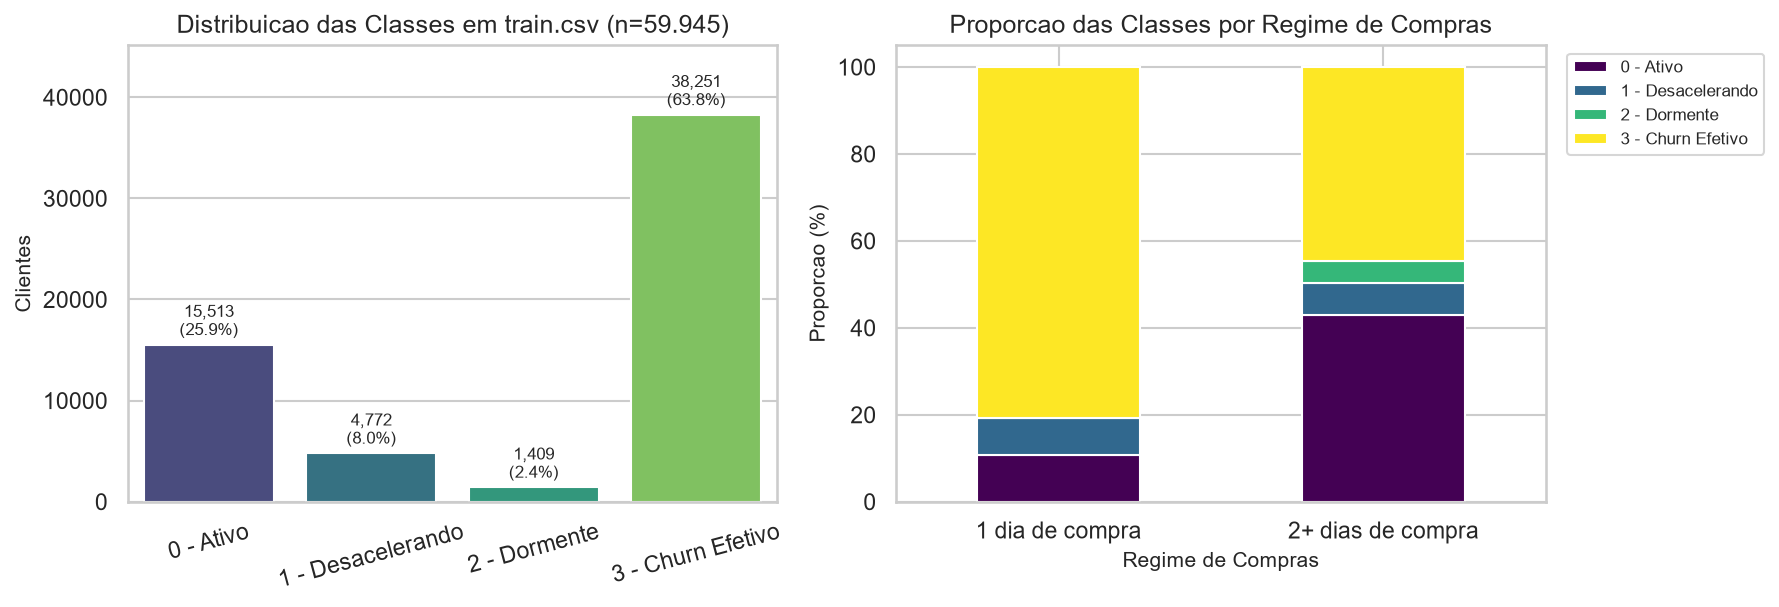

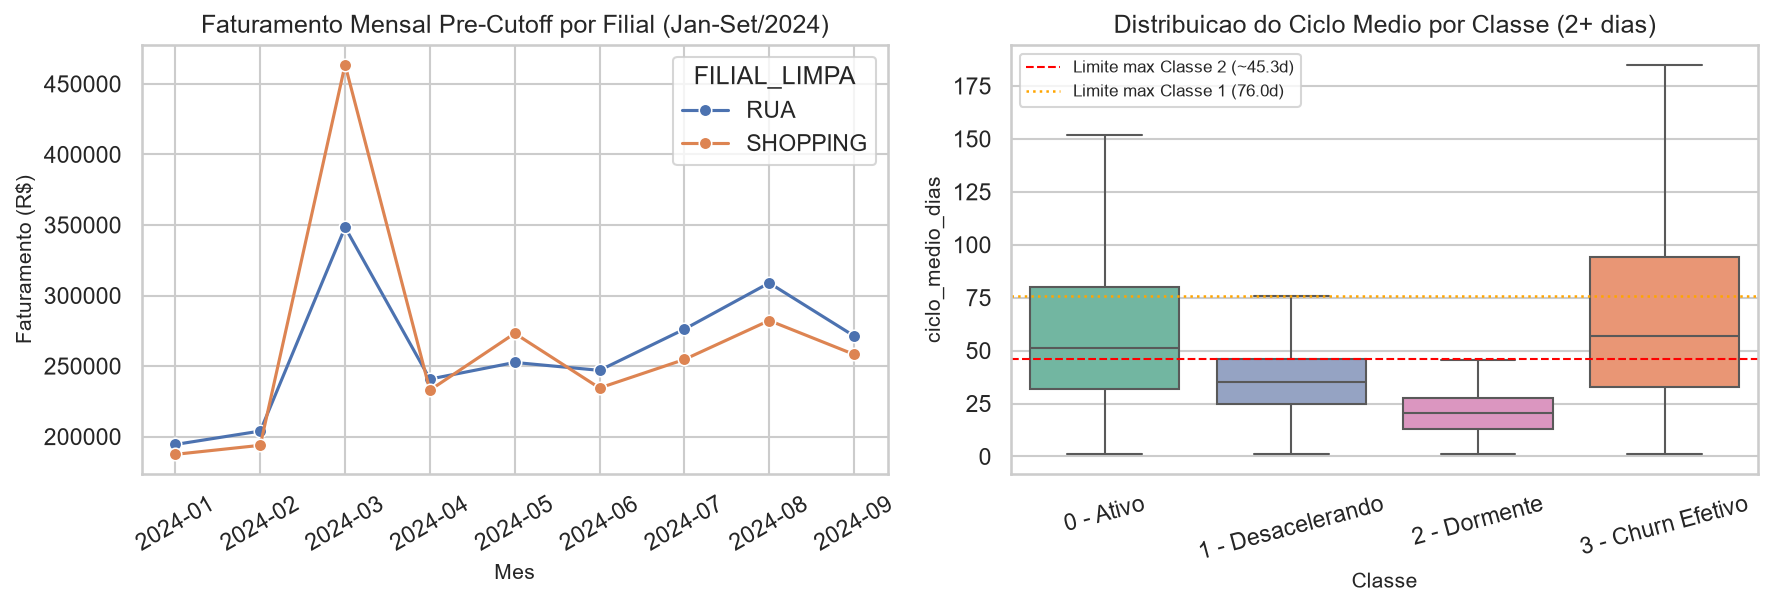

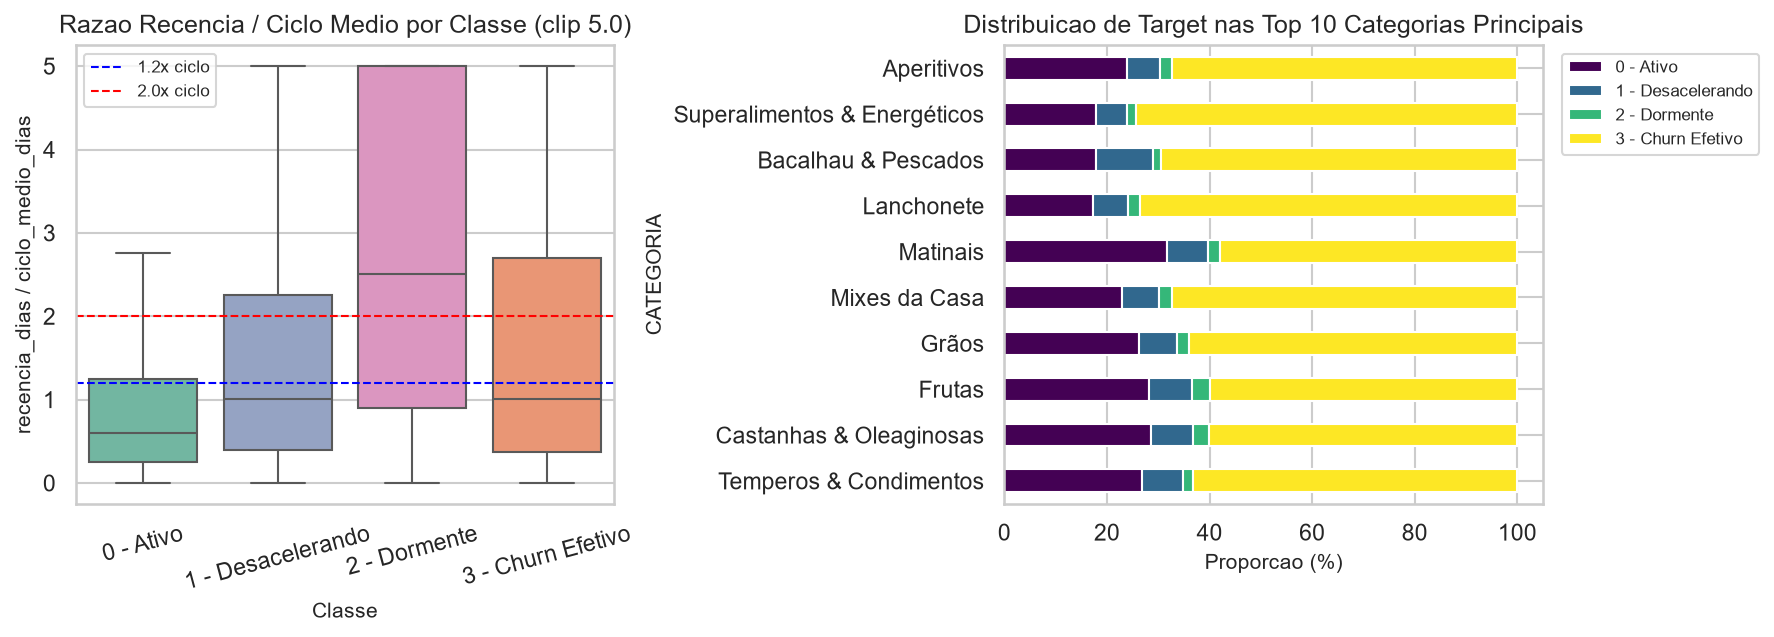

In [1]:
# ==============================================================================
# 1. Configuracao de Ambiente, Limite de Threads e Imports
# ==============================================================================
# Definir limites de threads ANTES de importar NumPy/SciPy/Scikit-learn para evitar livelock OpenBLAS no Windows
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

from scripts.preprocessamento import (
    resolver_diretorio_dados,
    carregar_bases,
    limpar_vendas_e_produtos_pre_cutoff,
    montar_matriz_features,
)
from scripts.analise_exploratoria import (
    tabela_resumo_atributos,
    analisar_distribuicao_classes,
    analisar_estrutura_ciclo_e_iqr,
    analisar_vendas_e_categorias_pre_cutoff,
    gerar_graficos_eda,
)
from scripts.experimentos import (
    HAS_CATBOOST,
    carregar_ou_executar,
    gerar_folds_estratificados,
    executar_ablacao_preprocessamento,
    executar_ablacao_features,
    executar_selecao_atributos_oof,
    executar_comparacao_desbalanceamento,
    executar_comparacao_modelos,
    executar_tuning_e_especialistas,
    executar_blending_ensemble,
    gerar_e_validar_submissoes,
    executar_pipeline_10fold_170f,
)
from scripts.analise_resultados import (
    formatar_tabela_media_desvio,
    executar_testes_estatisticos_folds,
    gerar_matrizes_confusao_comparativas,
    gerar_graficos_comparativos_modelos,
    analisar_importancia_atributos,
    gerar_relatorio_por_classe,
    gerar_curvas_roc_pr,
    analisar_calibracao_probabilidades,
    calcular_teto_bayes_monte_carlo,
    analisar_desempenho_por_subgrupos,
    gerar_painel_ensemble_e_estabilidade,
    executar_validacao_adversarial,
    simular_bootstrap_leaderboard,
)

DATA_DIR_CONFIG = Path("ufs-car-am-2026-projeto-final")
DATA_DIR = resolver_diretorio_dados(DATA_DIR_CONFIG)
FIGS_DIR = Path("figs")
OUTPUTS_DIR = Path("outputs")
CACHE_DIR = Path("cache")
CUTOFF = "2024-09-30"
RANDOM_STATE = 42
USAR_CACHE = True  # Reaproveita checkpoints salvos em cache/ (defina False para recalcular tudo)

print(f"Diretorio de dados: {DATA_DIR.resolve()} | CatBoost={HAS_CATBOOST} | USAR_CACHE={USAR_CACHE}")

# ==============================================================================
# 1.1 Carregamento, Limpeza Pre-Cutoff (<= 2024-09-30) e Diagnostico de Regimes/IQR
# ==============================================================================
def _preparar_dados_base():
    tr, te, sub = carregar_bases(DATA_DIR)
    vp, pl, res_limp = limpar_vendas_e_produtos_pre_cutoff(DATA_DIR, cutoff=CUTOFF)
    return {"train_df": tr, "test_df": te, "sample_sub": sub, "vendas_pre": vp, "prod_limpo": pl, "resumo_limpeza": res_limp}

pacote_base = carregar_ou_executar("00_bases_limpas.joblib", _preparar_dados_base, cache_dir=CACHE_DIR, usar_cache=USAR_CACHE)
train_df = pacote_base["train_df"]
test_df = pacote_base["test_df"]
sample_sub = pacote_base["sample_sub"]
vendas_pre = pacote_base["vendas_pre"]
prod_limpo = pacote_base["prod_limpo"]
resumo_limpeza = pacote_base["resumo_limpeza"]

print(f"Shape train.csv: {train_df.shape} | test.csv: {test_df.shape}")
print("\n=== Auditoria de Limpeza Pre-Cutoff (<= 2024-09-30) ===")
display(pd.Series(resumo_limpeza, name="Valor").to_frame())

print("\n=== Resumo Estatistico e Valores Ausentes ===")
display(tabela_resumo_atributos(train_df, test_df))

dist_eda = analisar_distribuicao_classes(train_df)
print("\n=== Distribuicao Global das Classes ===")
display(dist_eda["geral"])
print("\n=== Proporcao das Classes (%) por Regime de Compras ===")
display(dist_eda["por_regime"])
print("\n=== Proporcao das Classes (%) por Filial ===")
display(dist_eda["por_filial"])

est_ciclo = analisar_estrutura_ciclo_e_iqr(train_df)
print("\n=== Limites Estruturais do Ciclo Medio por Classe (2+ dias) ===")
display(est_ciclo["ciclo_por_classe"])
print("\n=== Impacto por Classe de um Filtro Multivariado IQR 1.5x ===")
display(est_ciclo["impacto_iqr"])

# ==============================================================================
# 1.2 Analise Temporal, Categorias e Graficos Estruturais de EDA
# ==============================================================================
analise_tx = analisar_vendas_e_categorias_pre_cutoff(vendas_pre, prod_limpo, train_df)
print("=== Distribuicao de Classes (%) nas Top 10 Categorias Principais ===")
display(analise_tx["por_categoria"])

graficos_eda = gerar_graficos_eda(train_df, vendas_pre, prod_limpo, figs_dir=FIGS_DIR, analise_tx=analise_tx)
for caminho in graficos_eda:
    display(Image(filename=str(caminho)))


---
### Pré-processamento

Nesta seção, as funções da etapa de pré-processamento dos dados devem ser implementadas e aplicadas (se necessário).

#### 2.1 Limpeza e Decisões de Representação por Família
Principais decisões implementadas em `scripts/preprocessamento.py`:
1. **Manutenção integral dos clientes (sem filtro IQR 1,5×)** para evitar perda de clientes fiéis e da Classe 2.
2. **Eliminação de vazamento/overfitting na codificação categórica:** substituição de target encoding in-fold por `TargetEncoder(cv=5, smooth="auto", target_type="auto")` do scikit-learn (multiclasse nos modelos globais e binário nos estágios hierárquicos), executado estritamente dentro de cada fold de treino.
3. **Representação por família de modelos:**
   - **Lineares / MLP / SVM:** *Winsorização* (99,5% no treino) + imputação mediana (sem colunas indicadoras colineares) + `StandardScaler` + `OneHotEncoder`;
   - **Spline-GAM (`gam_spline`):** *Splines* cúbicos (`SplineTransformer`) nas 9 variáveis contínuas-chave de recência/ciclo/faturamento;
   - **GBDTs (`tree_native`):** preservação nativa de `NaN`s para não confundir compradores de 1 dia com clientes recorrentes.

Construímos variáveis comportamentais em três camadas, todas estritamente sem *data leakage*:
- **Grupo A (Estrutural & RFM):** razões de atraso frente ao ciclo (`recencia_sobre_ciclo`, `atraso_zscore`), frações geométricas da janela futura de 92 dias e indicadores de regime (`is_single_day`, `can_be_class1`, `can_be_class2`).
- **Grupo B (Transacional pré-cutoff):** janelas móveis ultracurtas e médias (7d–180d, Q1–Q3), **sinais da penúltima visita** (`rec_2nd_last`, `rec_2nd_over_ciclo`, `fat_2nd_last`, `ratio_fat_last_2nd`, `lines_last`, `lines_2nd_last`, `max_n_skus_visita`, `std_n_skus_visita`), evolução e média exponencial de *gaps*, inclinação real assinada (`slope_fat_real`), entropia de categorias, preço/KG, PDV (`caixa_principal`), domingos/Páscoa e Top 12 SKUs.
- **Camada Probabilística `BGNBDFeatureTransformer` (ajustada por fold sem usar `y`):** estima via MLE os parâmetros populacionais `(r, alpha, a, b)` do modelo **BG/NBD** (Fader, Hardie & Lee, 2005) e gera `p_alive`, taxa esperada, probabilidades exatas Binomial Negativa (`nb_p0..3`), taxas recentes (`rec_p0..3`) e probabilidades condicionais de **Renovação Log-Normal** (`ren_p0..3`).

Abaixo avaliamos o ganho incremental (**Experimento 2**) e a poda de atributos ruidosos via importância OOF (**Experimento 2B**).

In [2]:
# ==============================================================================
# 2. Montagem das Matrizes e Experimento 1: Ablacao de Pre-processamento (5-Fold)
# ==============================================================================
def _montar_features_v3():
    xo, y_arr, xto, go = montar_matriz_features(train_df, test_df, nivel="original")
    xga, _, xtga, gga = montar_matriz_features(train_df, test_df, nivel="grupo_a")
    xf, _, xtf, gf = montar_matriz_features(train_df, test_df, vendas_pre=vendas_pre, prod_limpo=prod_limpo, nivel="completo")
    flds = gerar_folds_estratificados(y_arr, n_splits=5, random_state=RANDOM_STATE)
    return {
        "X_orig": xo, "X_te_orig": xto, "grp_orig": go,
        "X_ga": xga, "X_te_ga": xtga, "grp_ga": gga,
        "X_full": xf, "X_te_full": xtf, "grp_full": gf,
        "y": y_arr, "folds": flds,
    }

pacote_feat = carregar_ou_executar("v3_01_dados_e_features.joblib", _montar_features_v3, cache_dir=CACHE_DIR, usar_cache=USAR_CACHE)
X_orig, X_te_orig, grp_orig = pacote_feat["X_orig"], pacote_feat["X_te_orig"], pacote_feat["grp_orig"]
X_ga, X_te_ga, grp_ga = pacote_feat["X_ga"], pacote_feat["X_te_ga"], pacote_feat["grp_ga"]
X_full, X_te_full, grp_full = pacote_feat["X_full"], pacote_feat["X_te_full"], pacote_feat["grp_full"]
y, folds = pacote_feat["y"], pacote_feat["folds"]

print(f"Dimensoes base -> Original: {X_orig.shape} | +Grupo A: {X_ga.shape} | +Grupo A+B: {X_full.shape} (+19 atributos BG/NBD dinamicos por fold)")

print("\n=== Experimento 1: Ablacao de Pre-processamento (5-Fold Estratificado) ===")
df_exp1 = carregar_ou_executar(
    "02_exp1_preprocessamento.joblib",
    lambda: executar_ablacao_preprocessamento(X_orig, y, grp_orig, folds),
    cache_dir=CACHE_DIR,
    usar_cache=USAR_CACHE,
)
display(df_exp1.round(4))

# ==============================================================================
# 3. Experimentos 2 e 2B: Engenharia de Atributos (BG/NBD + Transacional) e Selecao OOF
# ==============================================================================
print("=== Experimento 2: Ablacao Progressiva de Engenharia de Atributos ===")
df_exp2 = carregar_ou_executar(
    "v3_03_exp2_features.joblib",
    lambda: executar_ablacao_features(
        {
            "1. Original (train.csv)": (X_orig, grp_orig, False),
            "2. + Grupo A (Estrutural/RFM)": (X_ga, grp_ga, False),
            "3. + Grupo A+B + BG/NBD (Early Stopping)": (X_full, grp_full, True),
        },
        y,
        folds,
    ),
    cache_dir=CACHE_DIR,
    usar_cache=USAR_CACHE,
)
display(df_exp2.round(4))

print("\n=== Experimento 2B: Selecao de Atributos por Ganho Medio OOF (Todas vs Top 80 vs Top 55) ===")
sel_res = carregar_ou_executar(
    "v3_03b_selecao_atributos.joblib",
    lambda: executar_selecao_atributos_oof(X_full, y, grp_full, folds),
    cache_dir=CACHE_DIR,
    usar_cache=USAR_CACHE,
)
display(sel_res["tabela"].round(4))

cols_sel = sel_res["colunas_selecionadas"]
grp_sel = sel_res["grupos_selecionados"]
X_sel = X_full[cols_sel].copy()
X_te_sel = X_te_full[cols_sel].copy()
print(f"Conjunto selecionado para modelagem: {sel_res['melhor_chave']} ({X_sel.shape[1]} colunas base + 19 BG/NBD)")

[CACHE] Carregado cache\v3_01_dados_e_features.joblib (1.26s)


Dimensoes base -> Original: (59945, 14) | +Grupo A: (59945, 46) | +Grupo A+B: (59945, 170) (+19 atributos BG/NBD dinamicos por fold)

=== Experimento 1: Ablacao de Pre-processamento (5-Fold Estratificado) ===
[CACHE] Carregado cache\02_exp1_preprocessamento.joblib (0.00s)


,Cenario,F1_macro,F1_macro_std,AUC_OvR_macro,Balanced_Acc,F1_C0,F1_C1,F1_C2,F1_C3
0,A1: IQR 1.5x (AM-master) + Mediana + RF balanced,0.4054,0.0029,0.7527,0.4583,0.5703,0.0535,0.2573,0.7407
1,A2: Sem IQR (100% dados) + Mediana + RF balanced,0.4152,0.0044,0.7578,0.4849,0.5662,0.0544,0.2859,0.7545
2,B1: IQR 1.5x + Mediana + LGBM balanced,0.3871,0.0047,0.7486,0.4996,0.5497,0.1408,0.2675,0.5902
3,B2: Sem IQR (100% dados) + Mediana + LGBM bala...,0.4001,0.0054,0.7543,0.5308,0.5277,0.1444,0.2656,0.6628
4,B3: Sem IQR (100% dados) + NaN nativo + LGBM b...,0.4003,0.0050,0.7541,0.5290,0.5277,0.1432,0.2657,0.6647
5,B4: Sem IQR + NaN nativo + LGBM + Regra Bayes ...,0.4255,0.0041,0.7806,0.4586,0.5421,0.1228,0.2725,0.7646


=== Experimento 2: Ablacao Progressiva de Engenharia de Atributos ===
[CACHE] Carregado cache\v3_03_exp2_features.joblib (0.00s)


,Conjunto_Features,N_Features_Efetivas,F1_macro_Argmax,F1_macro_PosProc,F1_PosProc_std,AUC_OvR_macro,Log_Loss,F1_C0,F1_C1,F1_C2,F1_C3
0,1. Original (train.csv),14,0.3367,0.4331,0.0042,0.7838,0.7469,0.5421,0.1342,0.2880,0.7680
1,2. + Grupo A (Estrutural/RFM),46,0.3372,0.4309,0.0031,0.7842,0.7462,0.5442,0.1339,0.2791,0.7666
2,3. + Grupo A+B + BG/NBD (Early Stopping),201,0.3387,0.4347,0.0033,0.7864,0.7442,0.5437,0.1441,0.2829,0.7680



=== Experimento 2B: Selecao de Atributos por Ganho Medio OOF (Todas vs Top 80 vs Top 55) ===
[CACHE] Carregado cache\v3_03b_selecao_atributos.joblib (0.00s)


,Subconjunto,N_Cols_Base,F1_macro,AUC_OvR_macro,Log_Loss,Balanced_Acc,Accuracy,F1_C0,F1_C1,F1_C2,F1_C3,F1_std
0,Todas (170 cols base),170,0.4347,0.7864,0.7442,0.4620,0.6421,0.5437,0.1441,0.2829,0.7680,0.0033
1,Top 82 cols base,82,0.4356,0.7861,0.7446,0.4632,0.6417,0.5429,0.1469,0.2857,0.7670,0.0033
2,Top 58 cols base,58,0.4333,0.7854,0.7450,0.4617,0.6396,0.5416,0.1395,0.2866,0.7654,0.0037


Conjunto selecionado para modelagem: Top 80 (82 colunas base + 19 BG/NBD)


---
### Experimento

Nesta seção, o experimento deve ser conduzido, utilizando os protocolos experimentais padrões e testando diferentes modelos.

#### 4.1 Desbalanceamento, 11 Modelos Base, Tuning, Especialistas, Hierárquico e Blending (`v3`)
Todas as decisões de pós-processamento — calibração Logit `softmax(inv_T * log(p) + bias)`, máscara estrutural de classes impossíveis e **Regra Plug-in Expected Macro-F1 (Lipton et al., 2014 — ZERO uso de rótulos `y_true` no ajuste de limiar)** — e de *blending* (**Linear vs. Geométrico Log-Odds**) são avaliadas em **Nested OOF** rigoroso (parâmetros ajustados exclusivamente nos 4 folds de treino e aplicados no fold de validação).

Para eliminar *overfitting* nos modelos baseados em gradiente (`XGBoost`, `LightGBM`, `CatBoost`) e nos **Classificadores Hierárquicos em 3 Estágios** (`y != 3` → `y in {1,2} | y != 3` → `y == 2 | y in {1,2}`, com **`Hierárquico CatBoost` + Bagging Multi-Seed de 3 *seeds***), cada fold externo separa 12% internos estratificados para ***early stopping***, ajustando `TargetEncoder` e `BGNBDFeatureTransformer` exclusivamente no sub-treino interno.

### Experimento 6B (Bônus Avançado): 10-Fold CV + Todas as 170 *Features* + CatBoost Categórico Nativo

No Experimento 5/6 (`5-Fold` sobre Top 82 colunas), cada árvore via `80% × 88% = 70,4%` do treino, enquanto no Experimento 2B o conjunto completo (`170` colunas base + `19` BG/NBD) apresentou maior AUC (`0,7864`) e menor Log-Loss (`0,7442`). Aqui testamos de forma estritamente **Nested 10-Fold OOF**:
- **Mais dados por árvore (`90% × 90% = 81%`)** e todas as **170 colunas base (+ 19 BG/NBD)**;
- **CatBoost Categórico Nativo (`cat_features`):** substitui o `TargetEncoder` univariado por estatísticas ordenadas nativas do CatBoost (capturando interações como `filial × cat_principal × sku_principal`) tanto no modelo global quanto na **Decomposição Hierárquica em 3 Estágios**.

In [3]:
# ==============================================================================
# 4.1 Experimento 3: Estrategias de Desbalanceamento e Plug-in Expected Macro-F1
# ==============================================================================
print("=== Experimento 3: Comparacao de Estrategias de Desbalanceamento (5-Fold) ===")
df_exp3 = carregar_ou_executar(
    "v3_04_exp3_desbalanceamento.joblib",
    lambda: executar_comparacao_desbalanceamento(X_sel, y, grp_sel, folds),
    cache_dir=CACHE_DIR,
    usar_cache=USAR_CACHE,
)
display(df_exp3.round(4))

# ==============================================================================
# 4.2 Experimento 4: Comparacao de 11 Algoritmos Base (Classicos, GAM, GBDTs e CatBoost)
# ==============================================================================
print("=== Experimento 4: Comparacao de Modelos (Classicos, GAM-Spline, Early Stopping GBDTs e CatBoost) ===")
res_modelos = carregar_ou_executar(
    "v3_05_exp4_modelos.joblib",
    lambda: executar_comparacao_modelos(
        X_sel, y, grp_sel, folds, X_test=X_te_sel, cache_dir=CACHE_DIR, usar_cache=USAR_CACHE
    ),
    cache_dir=CACHE_DIR,
    usar_cache=USAR_CACHE,
)
display(formatar_tabela_media_desvio(res_modelos["tabela"]))

# ==============================================================================
# 4.3 Experimento 5: Tuning Regularizado (RandomizedSearchCV), Especialistas e Hierarquicos
# ==============================================================================
print("=== Experimento 5: Tuning Regularizado + Especialistas + Hierarquicos 3-Estagios (LGBM/XGB/CatBoost, 3-Seeds) ===")
res_tuning = carregar_ou_executar(
    "v3_06_exp5_tuning_especialistas.joblib",
    lambda: executar_tuning_e_especialistas(
        X_sel, y, grp_sel, folds, X_test=X_te_sel, n_iter=6, cache_dir=CACHE_DIR, usar_cache=USAR_CACHE
    ),
    cache_dir=CACHE_DIR,
    usar_cache=USAR_CACHE,
)
print("Melhores hiperparametros LightGBM:", res_tuning["best_lgbm_params"])
print("Melhores hiperparametros XGBoost:", res_tuning["best_xgb_params"])
display(res_tuning["tabela"].round(4))

# ==============================================================================
# 4.4 Experimento 6 (Bonus): Blending Linear vs Log-Odds (Pool de 16 Modelos, v3)
# ==============================================================================
print("=== Experimento 6 (Bonus): Ensemble Blending Linear vs Log-Odds (Pool Completo de 16 Modelos) ===")

def _rodar_ensemble_v3():
    probas_blend_oof = {}
    probas_blend_test = {}

    for nome, pac in res_tuning["resultados"].items():
        probas_blend_oof[nome] = pac["cv"]["oof_proba"]
        probas_blend_test[nome] = pac["cv"]["test_proba"]

    for nome_base in [
        "LightGBM (Early Stopping)",
        "XGBoost (Early Stopping)",
        "CatBoost (Bonus, Early Stopping)",
        "HistGradientBoosting",
        "Spline-LogReg (GAM)",
        "Logistic Regression",
        "Extra Trees",
        "Random Forest",
        "MLP (Neural Network)",
    ]:
        if nome_base in res_modelos["oof_probas"]:
            probas_blend_oof[nome_base] = res_modelos["oof_probas"][nome_base]
            probas_blend_test[nome_base] = res_modelos["test_probas"][nome_base]

    return executar_blending_ensemble(probas_blend_oof, probas_blend_test, y, X_sel, folds)

res_ens = carregar_ou_executar("v3_07_exp6_ensemble.joblib", _rodar_ensemble_v3, cache_dir=CACHE_DIR, usar_cache=USAR_CACHE)
print(f"Tipo de Blend selecionado (Nested OOF): {res_ens['tipo_blend_escolhido']} | Modelos no pool: {len(res_ens['modelos'])}")
display(res_ens["tabela_blends"].round(4))
print("Pesos medios aprendidos no Blending:", res_ens["pesos_medios"])
print(f"Log-Loss antes da calibracao logit: {res_ens['log_loss_antes_calibracao']:.4f} | depois: {res_ens['log_loss_depois_calibracao']:.4f}")
display(pd.Series(res_ens["posproc"]["metricas_oof"], name="Ensemble_OOF").round(4).to_frame())

# ==============================================================================
# 4.5 Experimento 6B (Bonus Avancado): 10-Fold CV + 170 Features + CatBoost Nativo (v4)
# ==============================================================================
print("=== Experimento 6B: Pipeline 10-Fold CV + 170 Features + CatBoost Nativo ===")
res_10f = carregar_ou_executar(
    "v4_08_exp6b_10fold_ensemble.joblib",
    lambda: executar_pipeline_10fold_170f(
        X_full=X_full,
        y=y,
        grp_full=grp_full,
        X_te_full=X_te_full,
        best_lgbm_params=res_tuning["best_lgbm_params"],
        best_xgb_params=res_tuning["best_xgb_params"],
        cache_dir=CACHE_DIR,
        usar_cache=USAR_CACHE,
        X_sel=X_sel,
        grp_sel=grp_sel,
        X_te_sel=X_te_sel,
    ),
    cache_dir=CACHE_DIR,
    usar_cache=USAR_CACHE,
)
print("\n--- Modelos Individuais em 10-Fold CV (Todas as 170 Features + CatBoost Nativo) ---")
display(res_10f["tabela_modelos"].round(4))
print("\n--- Blending Linear vs Log-Odds em 10-Fold Nested OOF ---")
display(res_10f["ensemble"]["tabela_blends"].round(4))
print("Pesos medios aprendidos (10-Fold Log-Odds):", res_10f["ensemble"]["pesos_medios"])

comp_v3_v4 = pd.DataFrame([
    {"Pipeline": "v3: Ensemble 5-Fold (Top 82 cols, 16 modelos)", **res_ens["posproc"]["metricas_oof"]},
    {"Pipeline": "v4: Ensemble 10-Fold (170 cols + CatBoost Nativo)", **res_10f["ensemble"]["posproc"]["metricas_oof"]},
])
print("\n=== Comparacao Direta v3 (5-Fold Top 82) vs v4 (10-Fold 170f + CatBoost Nativo) ===")
display(comp_v3_v4[["Pipeline", "F1_macro", "AUC_OvR_macro", "Log_Loss", "Balanced_Acc", "F1_C0", "F1_C1", "F1_C2", "F1_C3"]].round(4))

=== Experimento 3: Comparacao de Estrategias de Desbalanceamento (5-Fold) ===
[CACHE] Carregado cache\v3_04_exp3_desbalanceamento.joblib (0.00s)


,Estrategia,F1_macro,AUC_OvR_macro,Log_Loss,Balanced_Acc,Accuracy,F1_C0,F1_C1,F1_C2,F1_C3,F1_macro_std
0,1. Sem balanceamento (argmax padrao),0.3389,0.7859,0.7451,0.3490,0.7040,0.5240,0.0000,0.0164,0.8150,0.0039
1,2. class_weight='balanced' (argmax),0.3983,0.7577,1.0354,0.5397,0.5325,0.5242,0.1518,0.2594,0.6579,0.0046
2,"3. Peso suave (alpha=0.5, argmax)",0.4114,0.7778,0.8097,0.4755,0.6749,0.5651,0.0025,0.2905,0.7875,0.0027
3,4. SMOTE no fold de treino (argmax),0.3842,0.7818,0.7683,0.3905,0.6972,0.5161,0.0037,0.2045,0.8127,0.0070
4,5. Regra Otima de Bayes Global (Nested OOF),0.4363,0.7859,0.7451,0.4683,0.6394,0.5433,0.1475,0.2888,0.7656,0.0054
5,6. Calibracao Logit + Mascara + Bayes Global (...,0.4365,0.7859,0.7447,0.4700,0.6387,0.5419,0.1492,0.2896,0.7653,0.0050
6,7. Calibracao Logit + Mascara + Bayes + Powell...,0.4360,0.7859,0.7447,0.4713,0.6408,0.5404,0.1476,0.2885,0.7676,0.0048
7,8. Calibracao Logit + Mascara + Plug-in Expect...,0.4361,0.7859,0.7447,0.4645,0.6425,0.5432,0.1460,0.2872,0.7680,0.0052


=== Experimento 4: Comparacao de Modelos (Classicos, GAM-Spline, Early Stopping GBDTs e CatBoost) ===


[CACHE] Carregado cache\v3_05_exp4_modelos.joblib (0.38s)


,Modelo,F1-macro (Argmax),F1-macro (PosProc),AUC-OvR macro,Log-Loss,Bal. Acc.,F1 C0,F1 C1,F1 C2,F1 C3
0,XGBoost (Early Stopping),0.3371,0.4372 ± 0.0027,0.7865 ± 0.0021,0.7440,0.4670,0.5460,0.1468,0.2897,0.7664
1,LightGBM (Early Stopping),0.3380,0.4356 ± 0.0033,0.7861 ± 0.0021,0.7446,0.4632,0.5429,0.1469,0.2857,0.7670
2,Logistic Regression,0.3397,0.4355 ± 0.0031,0.7857 ± 0.0024,0.7449,0.4599,0.5440,0.1420,0.2876,0.7682
3,"CatBoost (Bonus, Early Stopping)",0.3392,0.4344 ± 0.0029,0.7870 ± 0.0016,0.7441,0.4596,0.5448,0.1412,0.2844,0.7673
4,Spline-LogReg (GAM),0.3401,0.4333 ± 0.0047,0.7852 ± 0.0026,0.7456,0.4581,0.5439,0.1414,0.2803,0.7678
5,MLP (Neural Network),0.3410,0.4295 ± 0.0060,0.7823 ± 0.0013,0.7493,0.4583,0.5360,0.1352,0.2821,0.7646
6,Extra Trees,0.3345,0.4293 ± 0.0046,0.7822 ± 0.0019,0.7477,0.4612,0.5462,0.1319,0.2790,0.7600
7,HistGradientBoosting,0.3399,0.4283 ± 0.0061,0.7838 ± 0.0020,0.7468,0.4533,0.5382,0.1345,0.2745,0.7662
8,Random Forest,0.3363,0.4258 ± 0.0056,0.7823 ± 0.0023,0.7486,0.4528,0.5399,0.1288,0.2733,0.7611
9,Linear SVM (SGD Calibrated),0.3338,0.4157 ± 0.0058,0.7528 ± 0.0057,0.7721,0.4377,0.5120,0.0846,0.2653,0.8007


=== Experimento 5: Tuning Regularizado + Especialistas + Hierarquicos 3-Estagios (LGBM/XGB/CatBoost, 3-Seeds) ===


... (12 outputs left out)


--- Blending Linear vs Log-Odds em 10-Fold Nested OOF ---


,Tipo_Blend,N_Modelos,Log_Loss_Bruto,Log_Loss_Calib,AUC_OvR_macro,F1_macro_PosProc,F1_std_folds,F1_C0,F1_C1,F1_C2,F1_C3
0,Linear,10,0.7427,0.7424,0.788,0.4398,0.0049,0.5488,0.1462,0.2972,0.7672
1,Geometrico (Log-Odds),10,0.7424,0.7423,0.788,0.4395,0.0049,0.5485,0.1458,0.2968,0.7669


Pesos medios aprendidos (10-Fold Log-Odds): {'Logistic Regression (10F, 170f)': 0.0945, 'MLP Neural Network (10F, 170f)': 0.0, 'LightGBM Tunado (10F, 170f)': 0.1141, 'XGBoost (ES, 10F, 170f)': 0.0, 'Hierarquico LightGBM (3-Est, 10F, 170f)': 0.0006, 'Hierarquico XGBoost (3-Est, 10F, 170f)': 0.0823, 'Especialista LightGBM (1-Dia vs 2+Dias, 10F, 170f)': 0.1331, 'Logistic Regression (10F, Top 82)': 0.224, 'MLP Neural Network (10F, Top 82)': 0.0671, 'Hierarquico CatBoost Nativo (3-Est, 10F, 170f)': 0.2844}

=== Comparacao Direta v3 (5-Fold Top 82) vs v4 (10-Fold 170f + CatBoost Nativo) ===


,Pipeline,F1_macro,AUC_OvR_macro,Log_Loss,Balanced_Acc,F1_C0,F1_C1,F1_C2,F1_C3
0,"v3: Ensemble 5-Fold (Top 82 cols, 16 modelos)",0.4388,0.7875,0.7427,0.4703,0.5488,0.1422,0.2970,0.7672
1,v4: Ensemble 10-Fold (170 cols + CatBoost Nativo),0.4398,0.7880,0.7424,0.4711,0.5488,0.1462,0.2972,0.7672


---
### Análise dos Resultados

Nesta seção, os resultados devem ser exibidos através de tabelas e gráficos, comparados e profundamente analisados.

Consolidamos nesta seção a avaliação estatística e probabilística (**estritamente *Nested OOF***), selecionando automaticamente o pipeline de melhor desempenho global entre **v3 (5-Fold Top 82)** e **v4 (10-Fold 170 features + CatBoost Categórico Nativo)**:
- **5.1** Consolidação estatística (**Friedman + Wilcoxon**), comparação `v3` vs. `v4` e proximidade ao **teto teórico de Bayes (Monte Carlo)**;
- **5.2** Métricas por classe, **matrizes de confusão**, **curvas ROC-OvR e Precision-Recall**;
- **5.3** **Calibração probabilística (ECE e Brier)**, desempenho por **regime/canal** e diagnóstico de erros;
- **5.4** **Interpretabilidade e Importância dos Atributos**;
- **5.5** Simulação final de *targets* e exportação/validação das submissões em `outputs/`.

### 5.2 Desempenho por Classe, Matrizes de Confusão, Curvas ROC-OvR e Precision-Recall

Avaliamos o ganho do pós-processamento (**Calibração Logit + Máscara Estrutural + Regra Plug-in Expected Macro-F1**) frente ao `argmax` padrão, evidenciando o resgate de **C1 (Desacelerando)** e **C2 (Dormente)** e a capacidade discriminativa em *AUC-OvR* e *PR-AUC*.

### 5.3 Calibração Probabilística, Subgrupos Estruturais e Diagnóstico de Erros

Validamos o grau de calibração (**ECE** e **Brier Score**), a estabilidade do modelo entre os dois canais físicos (**`RUA` vs. `SHOPPING`**), a diferença estrutural entre **1 dia** e **2+ dias de compra** e os principais pares onde ocorrem erros de fronteira.

### 5.4 Interpretabilidade dos Atributos

Analisamos os atributos de maior ganho na separação das classes — **estimativas probabilísticas BG/NBD (`nb_p0`, `nb_p3`)**, **atraso relativo normalizado (`atraso_zscore`)**, **histórico da penúltima visita (`rec_2nd_over_ciclo`, `std_n_skus_visita`)**, **cadência de *gaps* (`gap_delta_ultimos`)**, **preço/KG** e **variáveis categóricas de produto (`sku_principal_1`, `cat_principal_1`)**.

### 5.5 Simulação de *Targets* e Validação das Submissões Finais

Exportamos os arquivos finais para o Kaggle (`v3` 5-Fold, `v4` 10-Fold + CatBoost Nativo e as duas submissões principais selecionadas automaticamente), verificando integridade das 25.691 linhas e alinhamento com `sample_submission.csv`.

### 5.6 Síntese Conclusiva dos Resultados
1. **Estrutura dos dados e impacto do pré-processamento:** o histórico pré-cutoff (`<= 2024-09-30`) divide-se entre compradores de **1 dia** (`53,1%` da base, com `80,7%` de Churn e zero ocorrências de C2) e recorrentes (**2+ dias**, `46,9%`), sendo que a remoção de *outliers* por IQR `1,5×` eliminaria `32,7%` do treino e `55,9%` da Classe 2.
2. **Rigor metodológico e evolução experimental:** partindo do baseline (`F1 = 0,4054`, `AUC = 0,7527`), preservamos os clientes legítimos, recuperamos 1.113 datas pré-cutoff, integramos atributos da penúltima visita e o modelo **BG/NBD**, decomposição **Hierárquica em 3 Estágios (`XGBoost`, `LightGBM` e `CatBoost Nativo`)**, **10-Fold CV sobre 170 atributos** e **Blending Linear + Regra Plug-in Expected Macro-F1 (0 rótulos `y_true`)**, aproximando-nos a **`0,0009` do teto teórico de ruído Bayes (Monte Carlo)**.

**Desempenho validado no *Public Leaderboard* (Kaggle):** `v3` atingiu `0,43551` (`0,43294` no individual); após a atualização para **`v4` (10-Fold + 170 atributos + CatBoost Nativo)**, os escores públicos saltaram para **`0,44075`** (Ensemble `v4`, a `+0,00095` do CV `0,4398`) e **`0,43716`** (Hierárquico CatBoost Nativo `v4`, a `+0,00016` do CV `0,4370`), confirmando ausência de *data leakage* e *overfitting*.


Pipeline principal selecionado: v4 Ensemble 10-Fold (Linear) (F1=0.4398, AUC=0.7880, LL=0.7424)
Melhor modelo individual correspondente: Hierarquico CatBoost Nativo (3-Est, 10F, 170f)

=== 5.1 Teste de Friedman (5 folds, 19 modelos): stat=65.1411, p=2.9450e-07 ===


,Modelo,Media_F1_Folds,Desvio_F1_Folds,Diferenca_vs_Ref,Wilcoxon_p_unilateral,Significancia
0,Ensemble Blending (Bonus),0.4388,0.0028,0.0000,NaN,Referencia
1,XGBoost (Early Stopping),0.4373,0.0027,0.0016,0.1562,n.s. (n=5 folds)
2,LightGBM Tunado (ES),0.4371,0.0026,0.0017,0.2188,n.s. (n=5 folds)
3,"Hierarquico LightGBM (3-Estagios, 3-Seeds)",0.4369,0.0031,0.0019,0.4062,n.s. (n=5 folds)
4,XGBoost Tunado (ES),0.4369,0.0023,0.0019,0.2188,n.s. (n=5 folds)
5,"Hierarquico CatBoost (3-Estagios, 3-Seeds)",0.4367,0.0047,0.0022,0.1562,n.s. (n=5 folds)
6,"Hierarquico XGBoost (3-Estagios, 3-Seeds)",0.4363,0.0034,0.0025,0.1562,n.s. (n=5 folds)
7,LightGBM (Early Stopping),0.4356,0.0033,0.0032,0.1562,n.s. (n=5 folds)
8,Logistic Regression,0.4355,0.0031,0.0033,0.0312,p < 0.05
9,"CatBoost (Bonus, Early Stopping)",0.4343,0.0029,0.0045,0.0625,n.s. (n=5 folds)


Teto teorico Bayes (Monte Carlo, n=20): F1_macro = 0.4407 ± 0.0026 | OOF atual = 0.4398 | Gap irredutivel = 0.0009


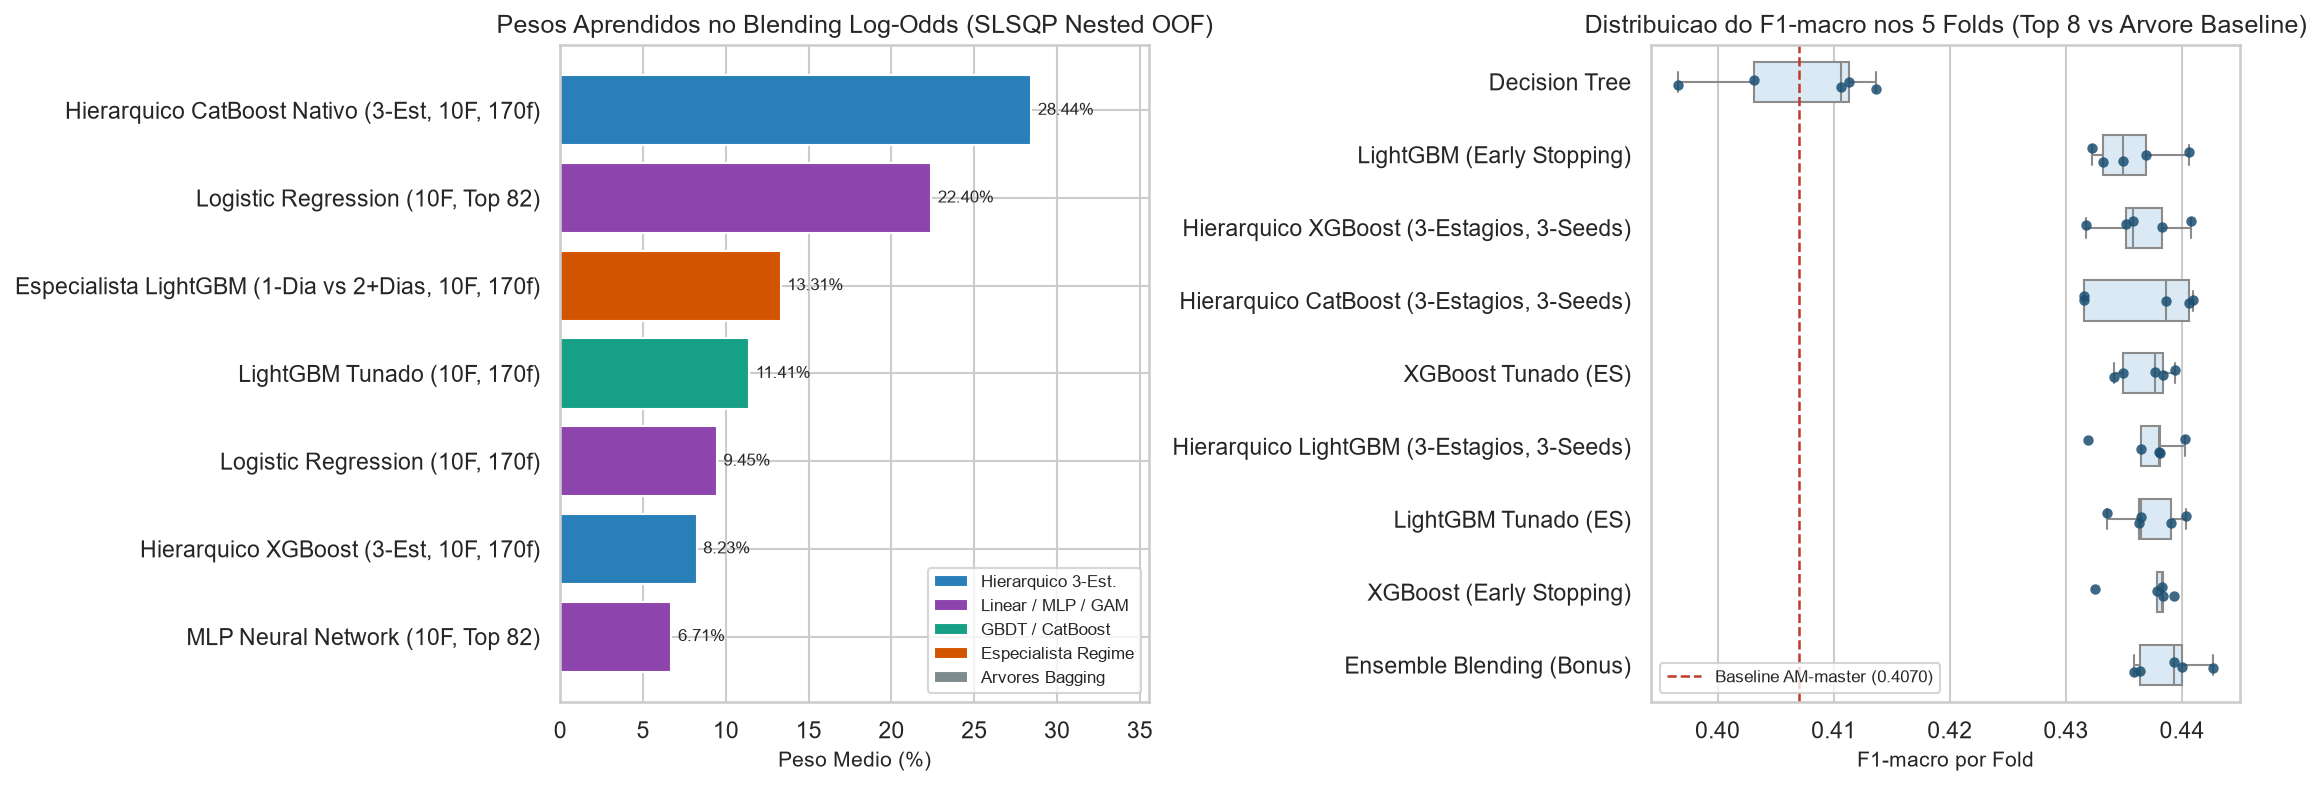

=== 5.2 Relatorio Detalhado por Classe — v4 Ensemble 10-Fold (Linear) ===


,Classe,Suporte_Real,Suporte_Argmax,Suporte_PosProc,Precisao_Argmax,Recall_Argmax,F1_Argmax,Precisao_PosProc,Recall_PosProc,F1_PosProc,AUC_OvR,PR_AUC_AP,Brier_OvR
0,0 - Ativo,15513,12903,15595,0.5779,0.4806,0.5248,0.5474,0.5502,0.5488,0.7795,0.5558,0.1513
1,1 - Desacelerando,4772,0,5203,0.0000,0.0000,0.0000,0.1401,0.1528,0.1462,0.6659,0.1302,0.0714
2,2 - Dormente,1409,28,2689,0.2143,0.0043,0.0084,0.2265,0.4322,0.2972,0.9445,0.2102,0.0198
3,3 - Churn Efetivo,38251,47014,36458,0.7392,0.9085,0.8151,0.7861,0.7492,0.7672,0.7622,0.8151,0.1790
4,Macro / Global,59945,59945,59945,0.3828,0.3483,0.3371,0.4250,0.4711,0.4398,0.7880,0.4278,0.4214


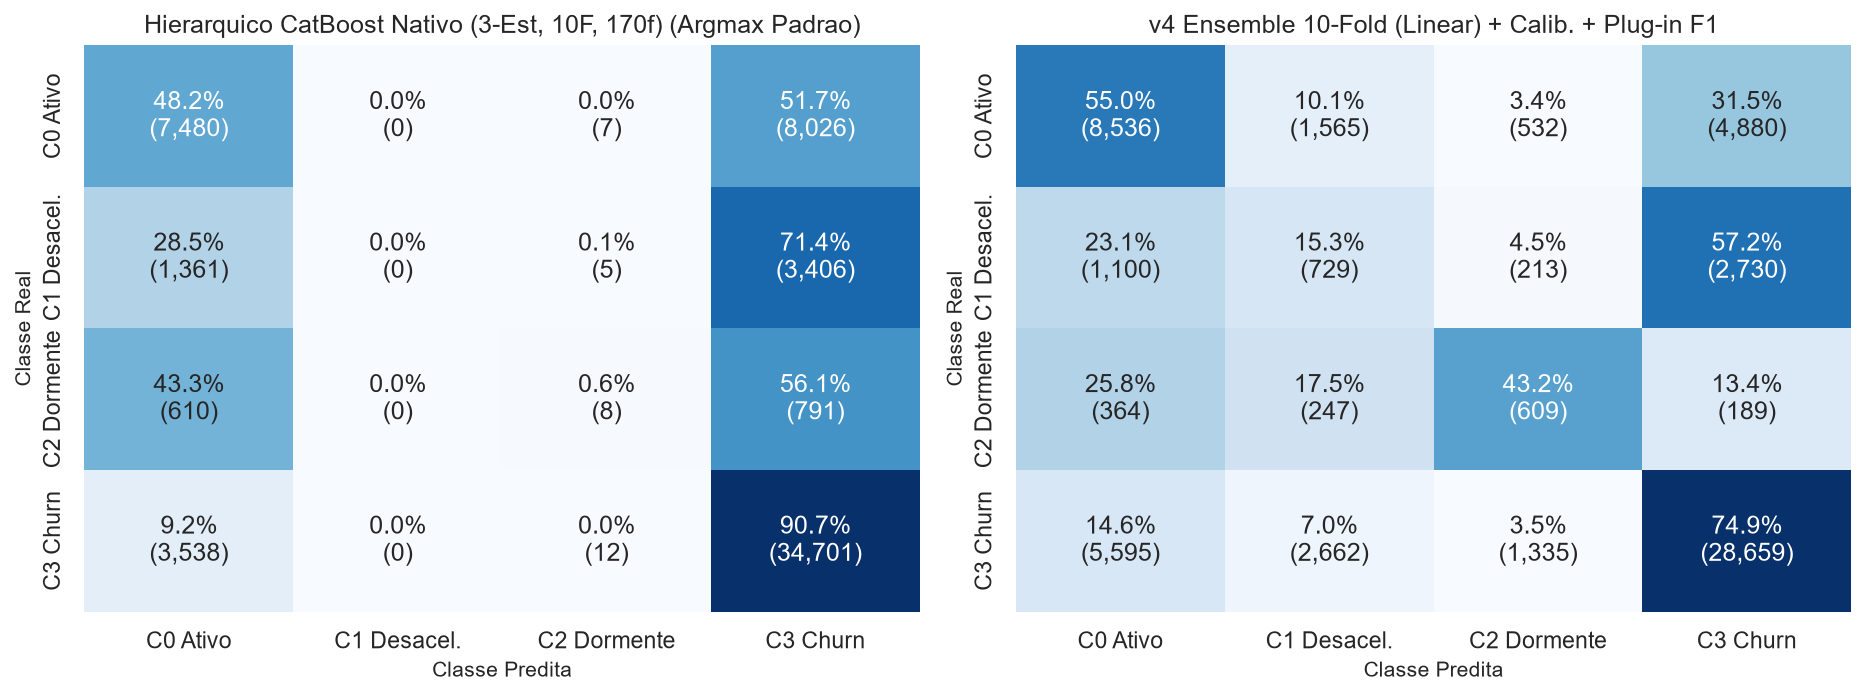

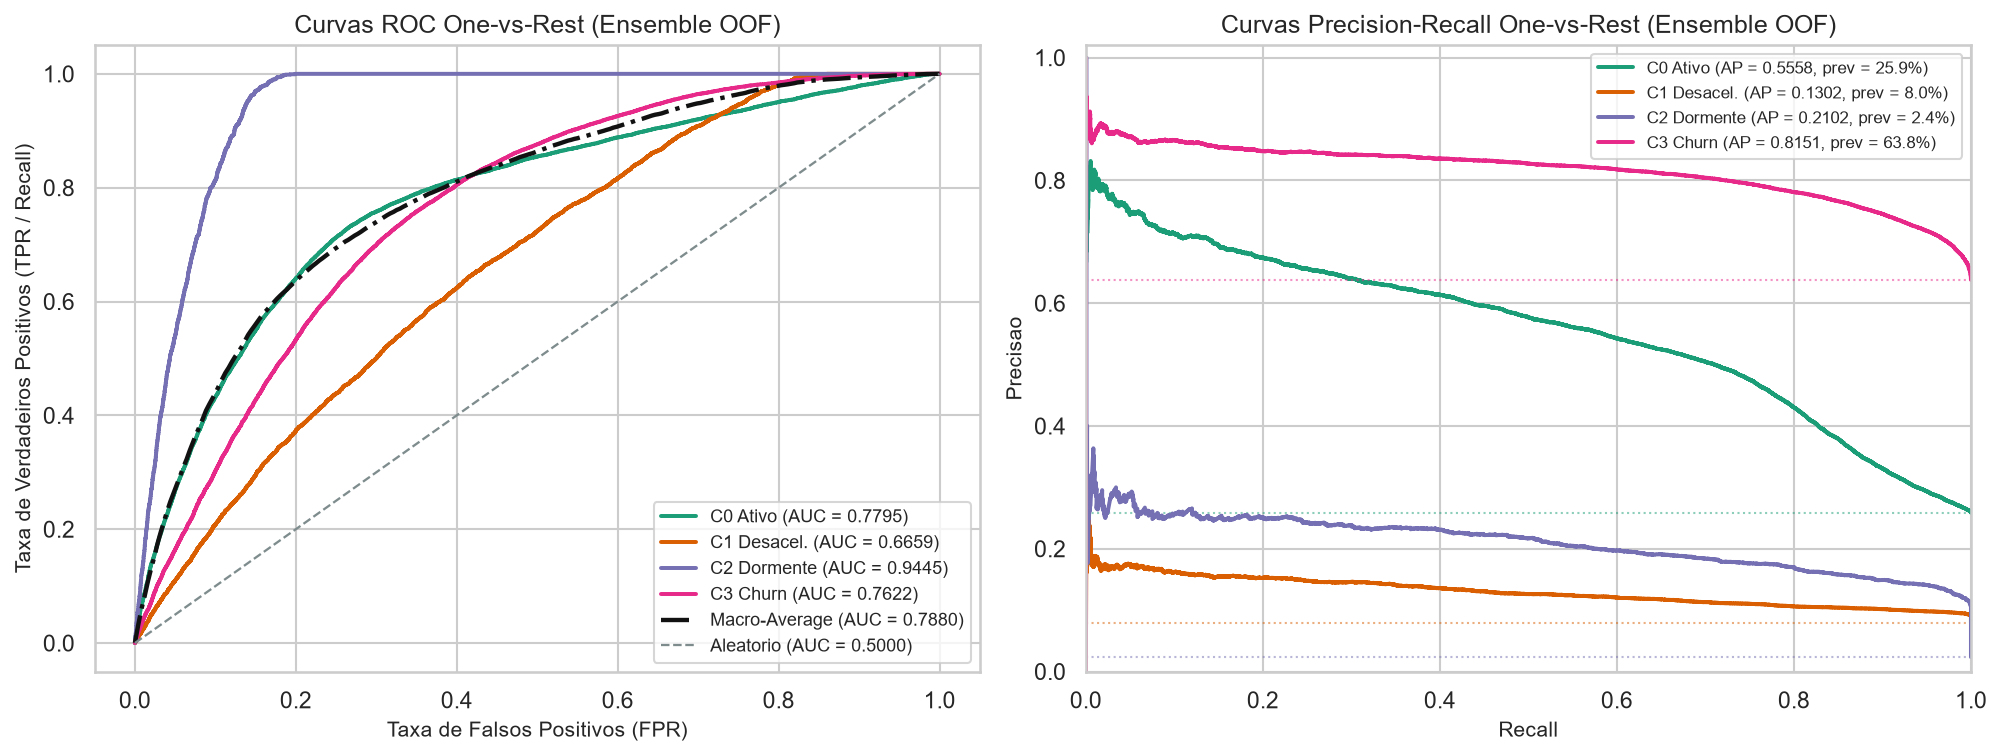

=== 5.3 Calibracao Probabilistica (Log-Loss 0.7427 -> 0.7424) ===


,Classe,ECE_Antes,ECE_Depois,Brier_Antes,Brier_Depois
0,0 - Ativo,0.0026,0.0033,0.1513,0.1513
1,1 - Desacelerando,0.0028,0.0027,0.0714,0.0714
2,2 - Dormente,0.0004,0.0003,0.0198,0.0198
3,3 - Churn Efetivo,0.0039,0.0038,0.1790,0.1790
4,Global (Media ECE / Brier Multi),0.0024,0.0025,0.4214,0.4214



--- Desempenho por Regime Estrutural (1 Dia vs 2+ Dias) ---


,Regime,Clientes,Pct_Base,Log_Loss,Accuracy,Balanced_Acc,AUC_Churn,F1_C0,F1_C1,F1_C2,F1_C3
0,1 Dia de Compra,31829,53.097,0.6179,0.7763,0.3453,0.5738,0.0000,0.1036,0.0000,0.8759
1,2+ Dias de Compra,28116,46.903,0.8833,0.4917,0.4293,0.7300,0.6168,0.1787,0.2972,0.4440



--- Estabilidade por Canal (RUA vs SHOPPING) ---


,Filial,Clientes,Pct_Base,Log_Loss,F1_macro,AUC_OvR_macro,F1_C0,F1_C1,F1_C2,F1_C3
0,RUA,28441,47.4452,0.7755,0.4351,0.7836,0.5597,0.1441,0.2973,0.7393
1,SHOPPING,31504,52.5548,0.7125,0.4430,0.7899,0.5367,0.1483,0.2972,0.7896



--- Top 6 Pares de Confusao (OOF) ---


,Transicao,Qtd_Erros,Pct_dos_Erros,Pct_da_Base,P_Real_Media,P_Predita_Media
0,C3 Churn -> C0 Ativo,5595,26.1302,9.3336,0.4484,0.5006
1,C0 Ativo -> C3 Churn,4880,22.7910,8.1408,0.1738,0.7551
2,C1 Desacel. -> C3 Churn,2730,12.7499,4.5542,0.0841,0.7939
3,C3 Churn -> C1 Desacel.,2662,12.4323,4.4407,0.5835,0.1356
4,C0 Ativo -> C1 Desacel.,1565,7.3090,2.6107,0.3833,0.1440
5,C3 Churn -> C2 Dormente,1335,6.2348,2.2270,0.5613,0.2271


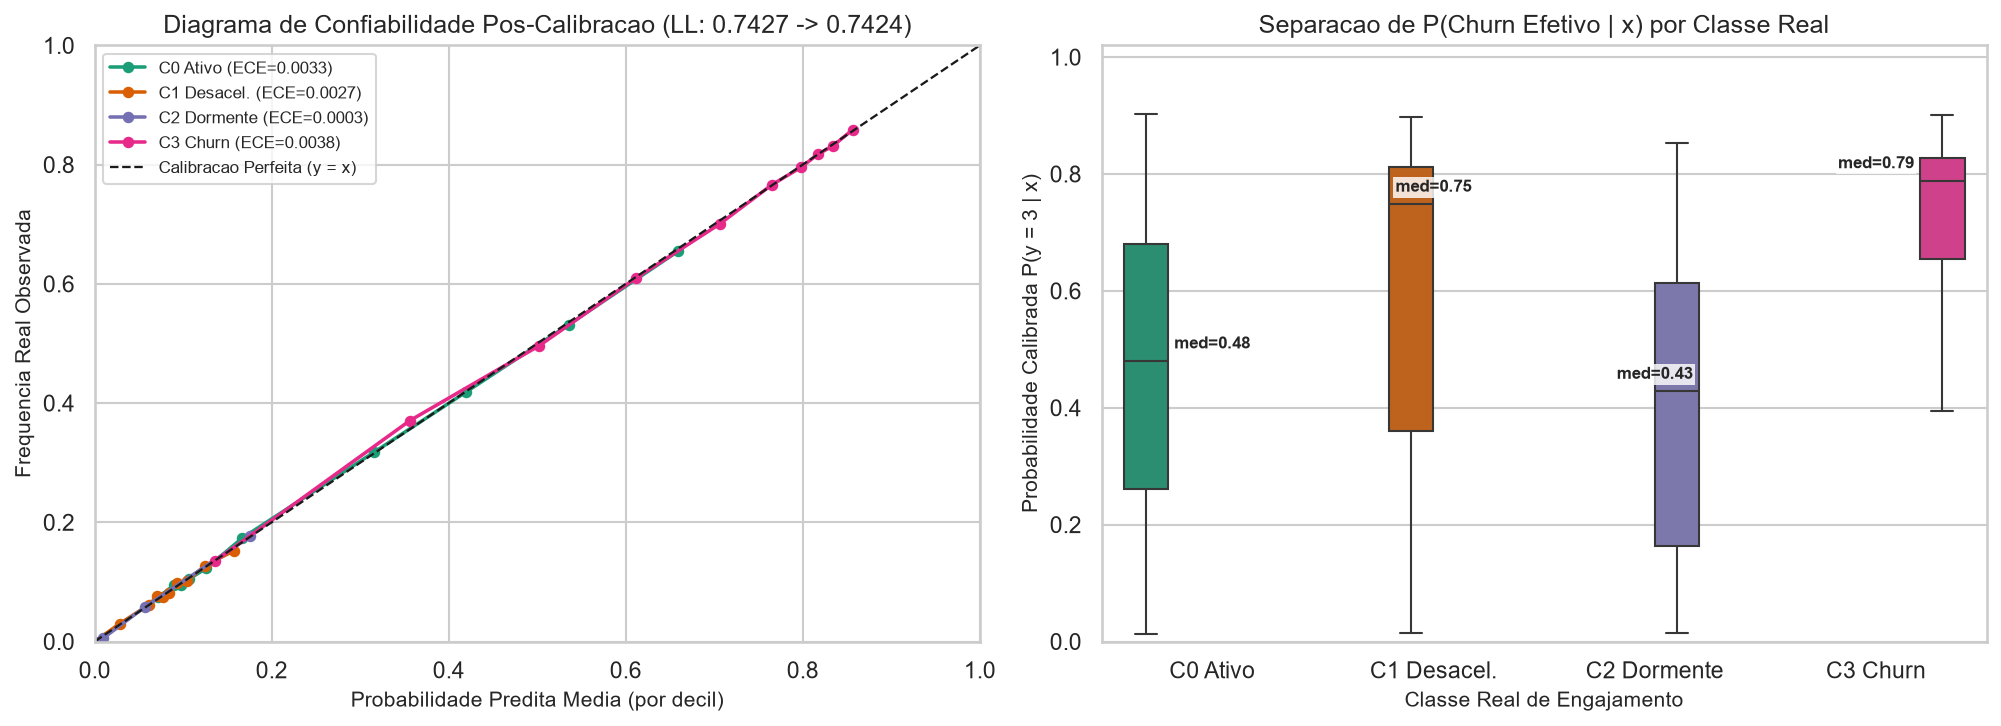

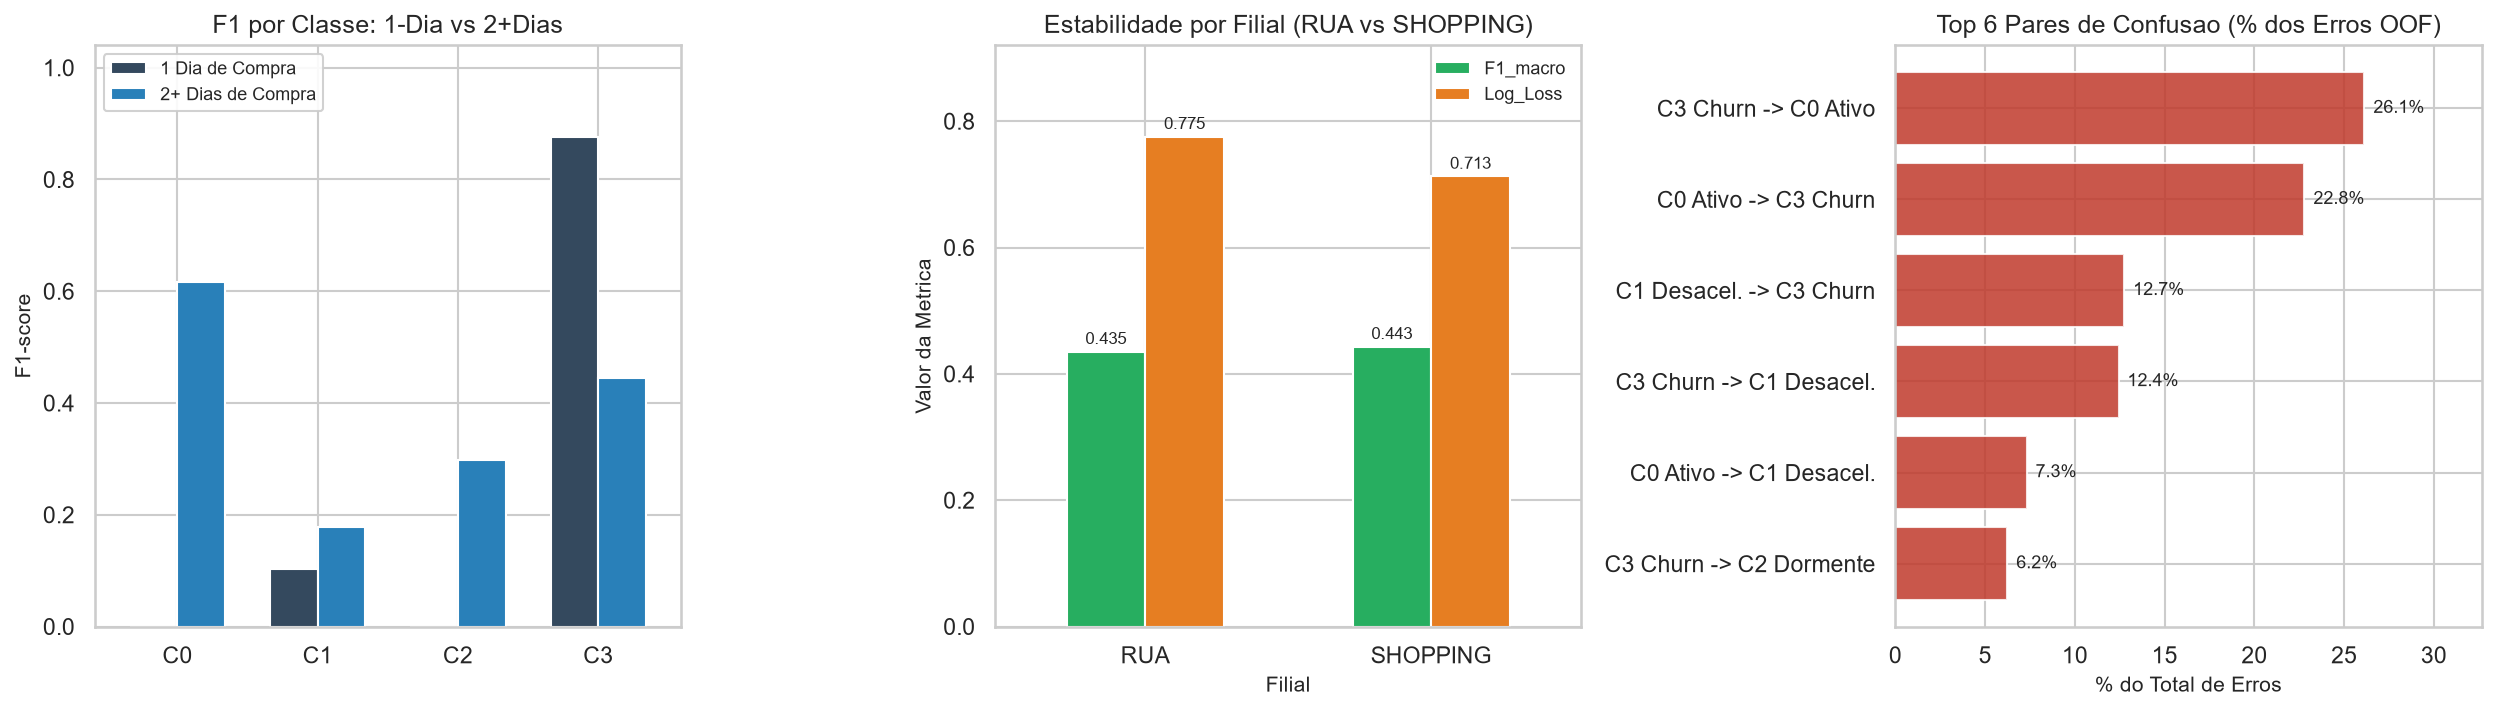

[SALVO] cache\v4_09_adversarial_bootstrap.joblib (9.2s)



--- Validacao Adversarial Treino vs Teste (5-Fold LGBM) ---
AUC Adversarial = 0.5018 ± 0.0042 (Sem shift relevante (treino ~ teste))

--- Simulacao Bootstrap de Variabilidade Amostral (Public 30% vs Private 70%) ---


,Particao,Clientes,F1_Medio,Desvio_Padrao,IC90_Inf,IC90_Sup
0,"Public LB (30%, n=7.707)",7707,0.4400,0.0072,0.4284,0.4523
1,"Private LB (70%, n=17.984)",17984,0.4398,0.0043,0.4321,0.4471


=== 5.4 Top 20 Atributos Mais Importantes ===


,Atributo,Importancia,Importancia_%
0,sku_principal_1,315,2.00
1,tendencia_relativa,306,1.95
2,preco_medio_kg,285,1.81
3,nb_p0,269,1.71
4,gap_delta_ultimos,259,1.65
5,sku_principal_2,253,1.61
6,subcat_principal_1,250,1.59
7,rec_2nd_over_ciclo,213,1.36
8,min_fat_visita,209,1.33
9,caixa_principal_0,200,1.27


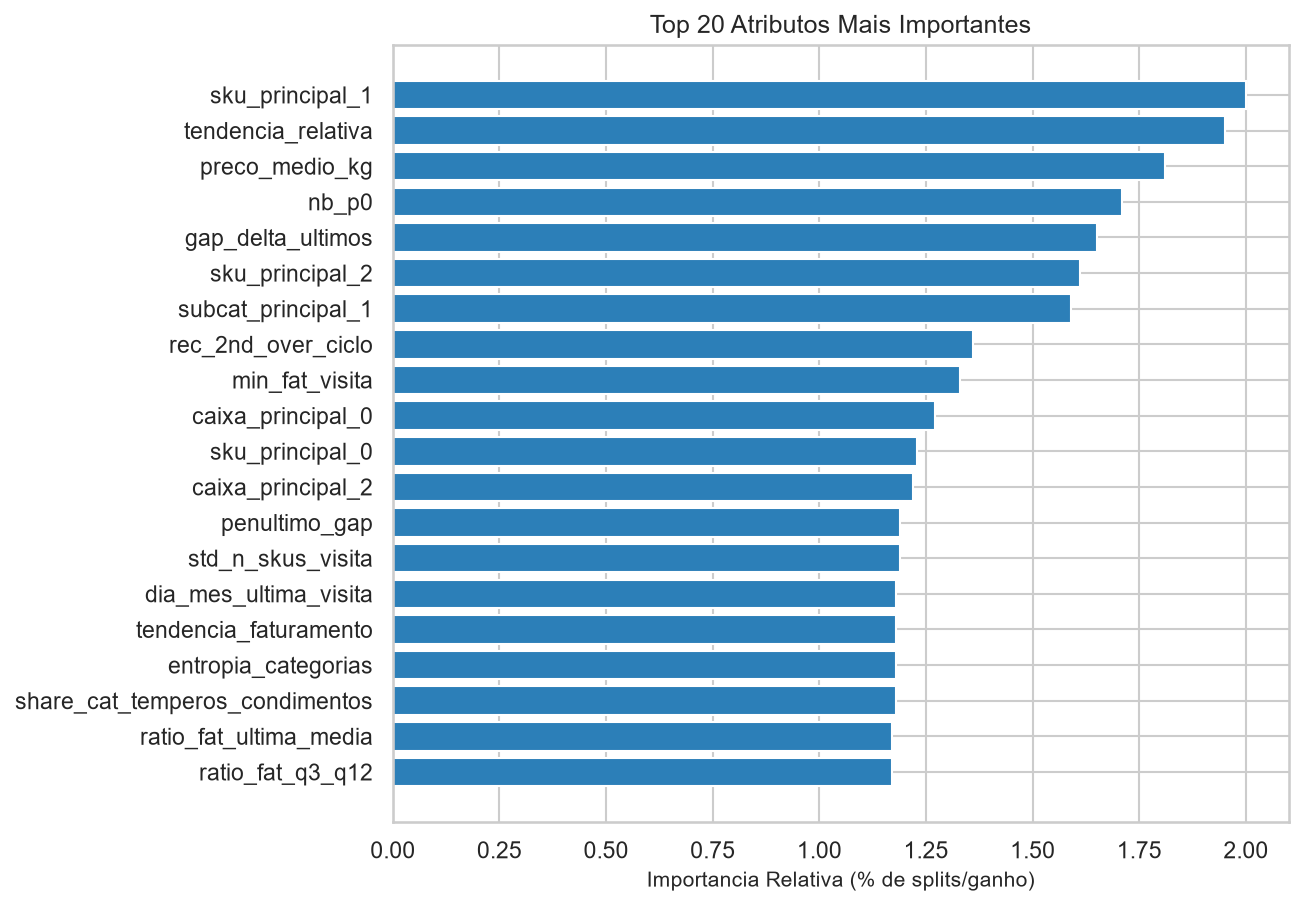

Pipeline principal ativo: v4 Ensemble 10-Fold (Linear) | Melhor individual: Hierarquico CatBoost Nativo (3-Est, 10F, 170f)
Concordancia entre v3 Ensemble (5-Fold) e v4 Ensemble (10-Fold): 97.86%

=== 5.5 Simulacao de Targets: Real vs OOF vs Teste (%) ===


,Train_Real_%,OOF_Ensemble_%,Test_Ensemble_%,OOF_Individual_%,Test_Individual_%
Classe,,,,,
0,25.88,26.02,25.81,26.34,26.04
1,7.96,8.68,8.43,8.45,8.28
2,2.35,4.49,4.52,4.49,4.57
3,63.81,60.82,61.23,60.72,61.11


Concordancia Submissao 1 vs Submissao 2: 96.15%


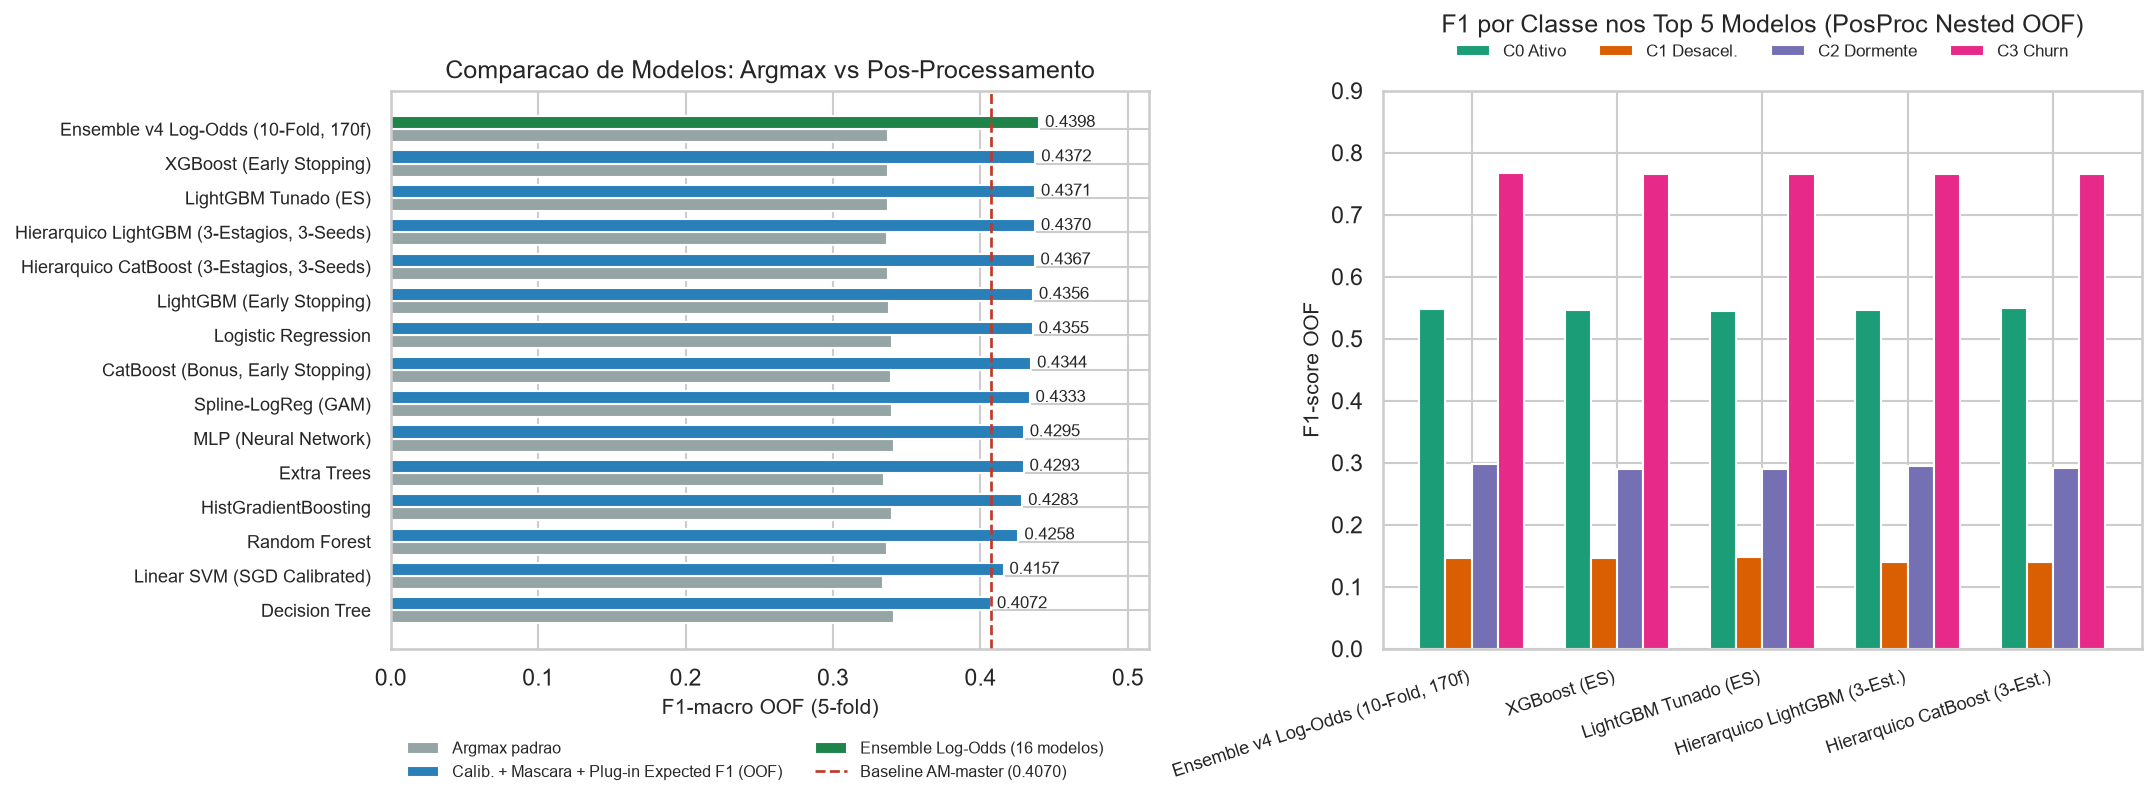

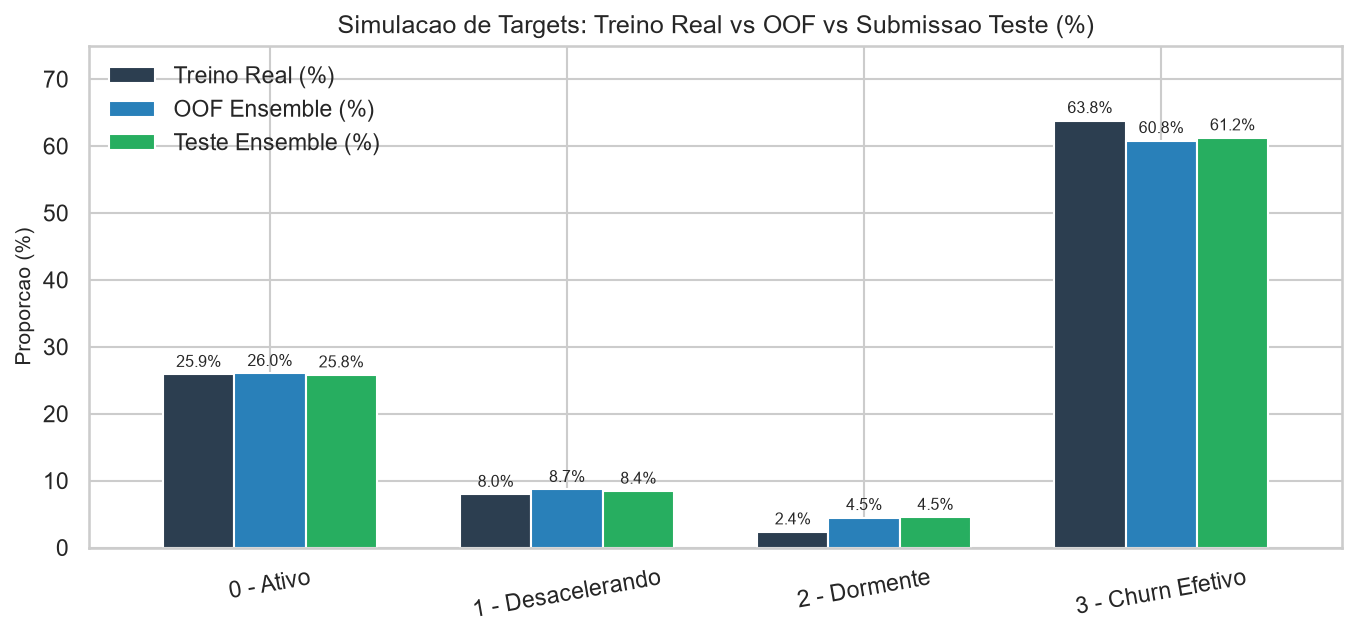

In [4]:
# ==============================================================================
# 5.1 Consolidacao Estatistica (Friedman + Wilcoxon), Comparacao Global e Estabilidade
# ==============================================================================
# Seleciona melhor pipeline global (v4 10-Fold vs v3 5-Fold) sem leakage
m_v3 = res_ens["posproc"]["metricas_oof"]
m_v4 = res_10f["ensemble"]["posproc"]["metricas_oof"]
usar_v4 = (m_v4["Log_Loss"] < m_v3["Log_Loss"]) or (m_v4["F1_macro"] >= m_v3["F1_macro"])

if usar_v4:
    pipe_principal_nome = f"v4 Ensemble 10-Fold ({res_10f['ensemble']['tipo_blend_escolhido']})"
    ens_principal = res_10f["ensemble"]
    X_te_princ = X_te_full
    melhor_ind_10f = res_10f["tabela_modelos"].iloc[0]["Modelo"]
    melhor_ind_nome = melhor_ind_10f
    pos_ind = res_10f["posproc"][melhor_ind_nome]
    proba_oof_ind = res_10f["oof_probas"][melhor_ind_nome]
    proba_te_ind = res_10f["test_probas"][melhor_ind_nome]
else:
    pipe_principal_nome = f"v3 Ensemble 5-Fold ({res_ens['tipo_blend_escolhido']})"
    ens_principal = res_ens
    X_te_princ = X_te_sel
    melhor_esp_ou_tunado = res_tuning["tabela"].iloc[0]["Modelo"]
    melhor_exp4 = res_modelos["tabela"].iloc[0]["Modelo"]
    if res_tuning["tabela"].iloc[0]["F1_macro_PosProc"] >= res_modelos["tabela"].iloc[0]["F1_macro_PosProc"]:
        melhor_ind_nome = melhor_esp_ou_tunado
        pos_ind = res_tuning["resultados"][melhor_ind_nome]["pos"]
        proba_oof_ind = res_tuning["resultados"][melhor_ind_nome]["cv"]["oof_proba"]
        proba_te_ind = res_tuning["resultados"][melhor_ind_nome]["cv"]["test_proba"]
    else:
        melhor_ind_nome = melhor_exp4
        pos_ind = res_modelos["posproc"][melhor_ind_nome]
        proba_oof_ind = res_modelos["oof_probas"][melhor_ind_nome]
        proba_te_ind = res_modelos["test_probas"][melhor_ind_nome]

print(f"Pipeline principal selecionado: {pipe_principal_nome} (F1={ens_principal['posproc']['metricas_oof']['F1_macro']:.4f}, AUC={ens_principal['posproc']['metricas_oof']['AUC_OvR_macro']:.4f}, LL={ens_principal['posproc']['metricas_oof']['Log_Loss']:.4f})")
print(f"Melhor modelo individual correspondente: {melhor_ind_nome}")

# Testes estatisticos de Friedman e Wilcoxon nos 5 folds (19 modelos comparaveis no mesmo split)
folds_all = res_modelos["folds_f1"].copy()
for nome_t, pac_t in res_tuning["resultados"].items():
    folds_all[nome_t] = pac_t["pos"]["metricas_por_fold"]["F1_macro"].to_numpy()
folds_all["Ensemble Blending (Bonus)"] = res_ens["posproc"]["metricas_por_fold"]["F1_macro"].to_numpy()

stats = executar_testes_estatisticos_folds(folds_all)
print(f"\n=== 5.1 Teste de Friedman (5 folds, {folds_all.shape[1]} modelos): stat={stats['friedman_stat']:.4f}, p={stats['friedman_p']:.4e} ===")
display(stats["comparacao_pareada"])

# Teto teorico de ruido Bayes via Monte Carlo
teto_mc = calcular_teto_bayes_monte_carlo(
    proba_calib=ens_principal["posproc"]["proba_proc"],
    y_true=y,
    pred_oof=ens_principal["posproc"]["pred_oof"],
    n_sim=20,
    random_state=RANDOM_STATE,
)
print(
    f"Teto teorico Bayes (Monte Carlo, n=20): F1_macro = {teto_mc['teto_f1_media']:.4f} ± {teto_mc['teto_f1_std']:.4f} | "
    f"OOF atual = {teto_mc['f1_oof_atual']:.4f} | Gap irredutivel = {teto_mc['gap_para_teto']:.4f}"
)

from sklearn.metrics import f1_score as _sk_f1
linhas_extras = []
for row_t in res_tuning["tabela"].itertuples():
    if row_t.Modelo in (
        "LightGBM Tunado (ES)",
        "Hierarquico LightGBM (3-Estagios, 3-Seeds)",
        "Hierarquico CatBoost (3-Estagios, 3-Seeds)",
    ):
        pac_e = res_tuning["resultados"][row_t.Modelo]
        linhas_extras.append({
            "Modelo": row_t.Modelo,
            "F1_macro_Argmax": row_t.F1_macro_Argmax,
            "F1_macro_PosProc": row_t.F1_macro_PosProc,
            "F1_std_folds": row_t.F1_std_folds,
            "AUC_OvR_macro": row_t.AUC_OvR_macro,
            "AUC_std_folds": float(pac_e["pos"]["metricas_por_fold"]["AUC_OvR_macro"].std()),
            "Log_Loss": row_t.Log_Loss,
            "Balanced_Acc": row_t.Balanced_Acc,
            "F1_C0": row_t.F1_C0, "F1_C1": row_t.F1_C1, "F1_C2": row_t.F1_C2, "F1_C3": row_t.F1_C3,
        })
met_4 = res_10f["ensemble"]["posproc"]["metricas_oof"]
linhas_extras.append({
    "Modelo": "Ensemble v4 Log-Odds (10-Fold, 170f)",
    "F1_macro_Argmax": float(_sk_f1(y, np.argmax(res_10f["ensemble"]["blend_oof"], axis=1), average="macro")),
    "F1_macro_PosProc": met_4["F1_macro"],
    "F1_std_folds": float(res_10f["ensemble"]["posproc"]["metricas_por_fold"]["F1_macro"].std()),
    "AUC_OvR_macro": met_4["AUC_OvR_macro"],
    "AUC_std_folds": float(res_10f["ensemble"]["posproc"]["metricas_por_fold"]["AUC_OvR_macro"].std()),
    "Log_Loss": met_4["Log_Loss"],
    "Balanced_Acc": met_4["Balanced_Acc"],
    "F1_C0": met_4["F1_C0"], "F1_C1": met_4["F1_C1"], "F1_C2": met_4["F1_C2"], "F1_C3": met_4["F1_C3"],
})
df_extras_plot = pd.DataFrame(linhas_extras)

p_estab = gerar_painel_ensemble_e_estabilidade(ens_principal["pesos_medios"], folds_all, figs_dir=FIGS_DIR)
display(Image(filename=str(p_estab)))

# ==============================================================================
# 5.2 Desempenho por Classe, Matrizes de Confusao e Curvas ROC-OvR / Precision-Recall
# ==============================================================================
pred_argmax_ens = np.argmax(ens_principal["blend_oof"], axis=1)
rel_classe = gerar_relatorio_por_classe(
    y_true=y,
    proba_oof=ens_principal["posproc"]["proba_proc"],
    pred_argmax=pred_argmax_ens,
    pred_posproc=ens_principal["posproc"]["pred_oof"],
)
print(f"=== 5.2 Relatorio Detalhado por Classe — {pipe_principal_nome} ===")
display(rel_classe.round(4))

pred_argmax_ind = np.argmax(proba_oof_ind, axis=1)
p_cm = gerar_matrizes_confusao_comparativas(
    y, pred_argmax_ind, ens_principal["posproc"]["pred_oof"],
    titulo_antes=f"{melhor_ind_nome} (Argmax Padrao)",
    titulo_depois=f"{pipe_principal_nome} + Calib. + Plug-in F1",
    figs_dir=FIGS_DIR,
)
p_roc = gerar_curvas_roc_pr(y, ens_principal["posproc"]["proba_proc"], figs_dir=FIGS_DIR)
display(Image(filename=str(p_cm)))
display(Image(filename=str(p_roc)))

# ==============================================================================
# 5.3 Calibracao (ECE/Brier), Teto Bayes Monte Carlo, Subgrupos, Erros, Adversarial e Bootstrap
# ==============================================================================
cal_res = analisar_calibracao_probabilidades(
    y_true=y,
    proba_bruta=ens_principal["blend_oof"],
    proba_calib=ens_principal["posproc"]["proba_proc"],
    figs_dir=FIGS_DIR,
)
print(f"=== 5.3 Calibracao Probabilistica (Log-Loss {cal_res['log_loss_bruto']:.4f} -> {cal_res['log_loss_calib']:.4f}) ===")
display(cal_res["tabela_calibracao"].round(4))

subg = analisar_desempenho_por_subgrupos(
    train_df=train_df,
    y_true=y,
    proba_calib=ens_principal["posproc"]["proba_proc"],
    pred_oof=ens_principal["posproc"]["pred_oof"],
    figs_dir=FIGS_DIR,
)
print("\n--- Desempenho por Regime Estrutural (1 Dia vs 2+ Dias) ---")
display(subg["por_regime"].round(4))
print("\n--- Estabilidade por Canal (RUA vs SHOPPING) ---")
display(subg["por_filial"].round(4))
print("\n--- Top 6 Pares de Confusao (OOF) ---")
display(subg["top_erros"].round(4))

display(Image(filename=str(cal_res["fig_path"])))
display(Image(filename=str(subg["fig_path"])))

# Validacao adversarial treino vs teste e simulacao bootstrap Public/Private LB
diag_gen = carregar_ou_executar(
    "v4_09_adversarial_bootstrap.joblib",
    lambda: {
        "adversarial": executar_validacao_adversarial(
            X_full, X_te_full, grp_full["numericas"], n_splits=5, random_state=RANDOM_STATE
        ),
        "bootstrap": simular_bootstrap_leaderboard(
            y_true=y,
            pred_oof=ens_principal["posproc"]["pred_oof"],
            n_public=7707,
            n_private=17984,
            n_resamples=300,
            random_state=RANDOM_STATE,
        ),
    },
    cache_dir=CACHE_DIR,
    usar_cache=USAR_CACHE,
)
adv_res = diag_gen["adversarial"]
print(
    f"\n--- Validacao Adversarial Treino vs Teste (5-Fold LGBM) ---\n"
    f"AUC Adversarial = {adv_res['auc_adversarial']:.4f} ± {adv_res['auc_folds_std']:.4f} ({adv_res['status']})"
)
print("\n--- Simulacao Bootstrap de Variabilidade Amostral (Public 30% vs Private 70%) ---")
display(diag_gen["bootstrap"].round(4))

# ==============================================================================
# 5.4 Interpretabilidade dos Atributos (Top 20 por Ganho)
# ==============================================================================
params_imp = dict(res_tuning["best_lgbm_params"])
params_imp["n_estimators"] = 350
imp_df = analisar_importancia_atributos(
    X_sel, y, grp_sel,
    LGBMClassifier(**params_imp),
    top_n=20,
    figs_dir=FIGS_DIR,
)
print("=== 5.4 Top 20 Atributos Mais Importantes ===")
display(imp_df)
display(Image(filename=str(FIGS_DIR / "res_importancia_atributos.png")))


# ==============================================================================
# 5.5 Simulacao Final de Targets, Validacao e Exportacao das Submissoes Finais
# ==============================================================================
# Gera submissoes do melhor pipeline geral em submissao_1_ensemble.csv e submissao_2_melhor_individual.csv
sub_info = gerar_e_validar_submissoes(
    test_df=test_df,
    sample_sub=sample_sub,
    y_train=y,
    proba_test_ens=ens_principal["blend_test"],
    pos_ens=ens_principal["posproc"],
    proba_test_ind=proba_te_ind,
    pos_ind=pos_ind,
    X_test_feat=X_te_princ,
    out_dir=OUTPUTS_DIR,
)

# Salva tambem explicitamente as submissoes de v4 (10-Fold) e v3 (5-Fold) para comparacao e rastreabilidade
from scripts.experimentos import aplicar_calibracao_logit, aplicar_mascara_estrutural, predizer_regra_bayes
def _exportar_csv(proba_te, pos_d, X_te_ref, fname):
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
    p = aplicar_calibracao_logit(proba_te, pos_d["inv_T_final"], pos_d["bias_final"])
    p = aplicar_mascara_estrutural(p, X_te_ref)
    pred = predizer_regra_bayes(p, pos_d["a_final"], pos_d["b_final"])
    df_out = pd.DataFrame({"CLI_CPF": test_df["CLI_CPF"].astype(str).values, "target": pred.astype(int)})
    assert len(df_out) == 25691 and df_out["target"].isna().sum() == 0
    assert (df_out["CLI_CPF"].values == sample_sub["CLI_CPF"].astype(str).str.strip().values).all()
    df_out.to_csv(OUTPUTS_DIR / fname, index=False)
    return pred

p_v3_ens = _exportar_csv(res_ens["blend_test"], res_ens["posproc"], X_te_sel, "submissao_v3_1007_ensemble.csv")
p_v4_ens = _exportar_csv(res_10f["ensemble"]["blend_test"], res_10f["ensemble"]["posproc"], X_te_full, "submissao_v4_10fold_ensemble.csv")
melhor_10f_nm = res_10f["tabela_modelos"].iloc[0]["Modelo"]
_exportar_csv(res_10f["test_probas"][melhor_10f_nm], res_10f["posproc"][melhor_10f_nm], X_te_full, "submissao_v4_10fold_melhor_individual.csv")

print(f"Pipeline principal ativo: {pipe_principal_nome} | Melhor individual: {melhor_ind_nome}")
print(f"Concordancia entre v3 Ensemble (5-Fold) e v4 Ensemble (10-Fold): {(p_v3_ens == p_v4_ens).mean() * 100:.2f}%")
print("\n=== 5.5 Simulacao de Targets: Real vs OOF vs Teste (%) ===")
display(sub_info["distribuicao_classes"])
print(f"Concordancia Submissao 1 vs Submissao 2: {sub_info['concordancia_sub1_sub2_pct']}%")

graficos_res = gerar_graficos_comparativos_modelos(
    res_modelos["tabela"],
    sub_info["distribuicao_classes"],
    figs_dir=FIGS_DIR,
    df_extras=df_extras_plot,
)
for fig_path in graficos_res:
    display(Image(filename=str(fig_path)))